# Module 03 — Linear Regression

**Applied exercises only** · ISLP, Chapter 3

**Printed textbook pages:** 129–133 (exercise starting pages)  

In [1]:
# Common imports and data: run this cell before the exercises.
# All data sets come from the ISLP package installed in the project's .venv.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from ISLP import load_data

rng = np.random.default_rng(1)

auto = load_data("Auto").reset_index()   # keep the car name as a regular column
carseats = load_data("Carseats")
boston = load_data("Boston")

print(f"Auto: {auto.shape}; columns={list(auto.columns)}")
print(f"Carseats: {carseats.shape}; columns={list(carseats.columns)}")
print(f"Boston: {boston.shape}; columns={list(boston.columns)}")

Auto: (392, 9); columns=['name', 'mpg', 'cylinders', 'displacement', 'horsepower', 'weight', 'acceleration', 'year', 'origin']
Carseats: (400, 11); columns=['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'ShelveLoc', 'Age', 'Education', 'Urban', 'US']
Boston: (506, 13); columns=['crim', 'zn', 'indus', 'chas', 'nox', 'rm', 'age', 'dis', 'rad', 'tax', 'ptratio', 'lstat', 'medv']


---

## Exercise 8 · Applied

**Textbook: printed page 129**

This question involves the use of simple linear regression on the Auto
data set.

### Exercise 8(a)

Use the sm.OLS() function to perform a simple linear regression
with mpg as the response and horsepower as the predictor. Use
the summarize() function to print the results. Comment on the
output. For example:
i. Is there a relationship between the predictor and the response?
ii. How strong is the relationship between the predictor and
the response?
iii. Is the relationship between the predictor and the response
positive or negative?
iv. What is the predicted mpg associated with a horsepower of
98? What are the associated 95 % confidence and prediction
intervals?

In [2]:
# Exercise 8(a)
fit_8 = smf.ols("mpg ~ horsepower", data=auto).fit()
print(fit_8.summary())

prediction_98 = fit_8.get_prediction(pd.DataFrame({"horsepower": [98]})).summary_frame(alpha=0.05)
print("\nPrediction at 98 horsepower (mean response and individual prediction intervals):")
display(prediction_98.round(3))
print(
    "The slope is negative and highly significant, so horsepower and mpg are associated. "
    f"R-squared={fit_8.rsquared:.3f} means horsepower alone explains about "
    f"{100 * fit_8.rsquared:.1f}% of the sample variation in mpg."
)

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.606
Model:                            OLS   Adj. R-squared:                  0.605
Method:                 Least Squares   F-statistic:                     599.7
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           7.03e-81
Time:                        19:52:55   Log-Likelihood:                -1178.7
No. Observations:                 392   AIC:                             2361.
Df Residuals:                     390   BIC:                             2369.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     39.9359      0.717     55.660      0.0

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,24.467,0.251,23.973,24.961,14.809,34.125


The slope is negative and highly significant, so horsepower and mpg are associated. R-squared=0.606 means horsepower alone explains about 60.6% of the sample variation in mpg.


### Exercise 8(b)

Plot the response and the predictor in a new set of axes ax. Use
the ax.axline() method or the abline() function defined in the
lab to display the least squares regression line.

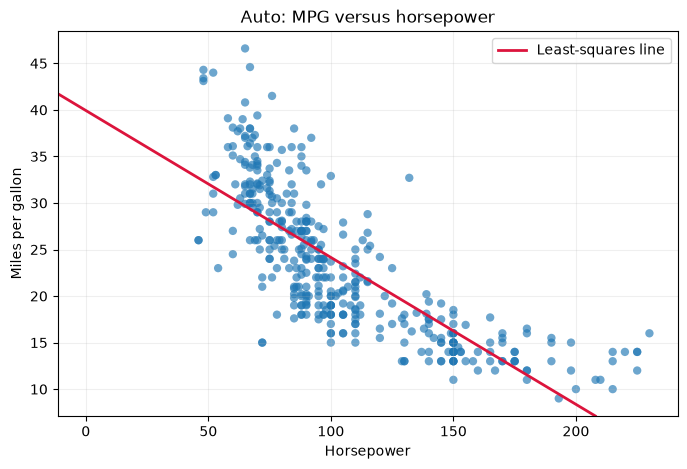

In [3]:
# Exercise 8(b)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(auto["horsepower"], auto["mpg"], alpha=0.65, edgecolor="none")
ax.axline(
    (0, fit_8.params["Intercept"]),
    slope=fit_8.params["horsepower"],
    color="crimson",
    linewidth=2,
    label="Least-squares line",
)
ax.set(title="Auto: MPG versus horsepower", xlabel="Horsepower", ylabel="Miles per gallon")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

### Exercise 8(c)

Produce some of diagnostic plots of the least squares regression
fit as described in the lab. Comment on any problems you see
with the fit.

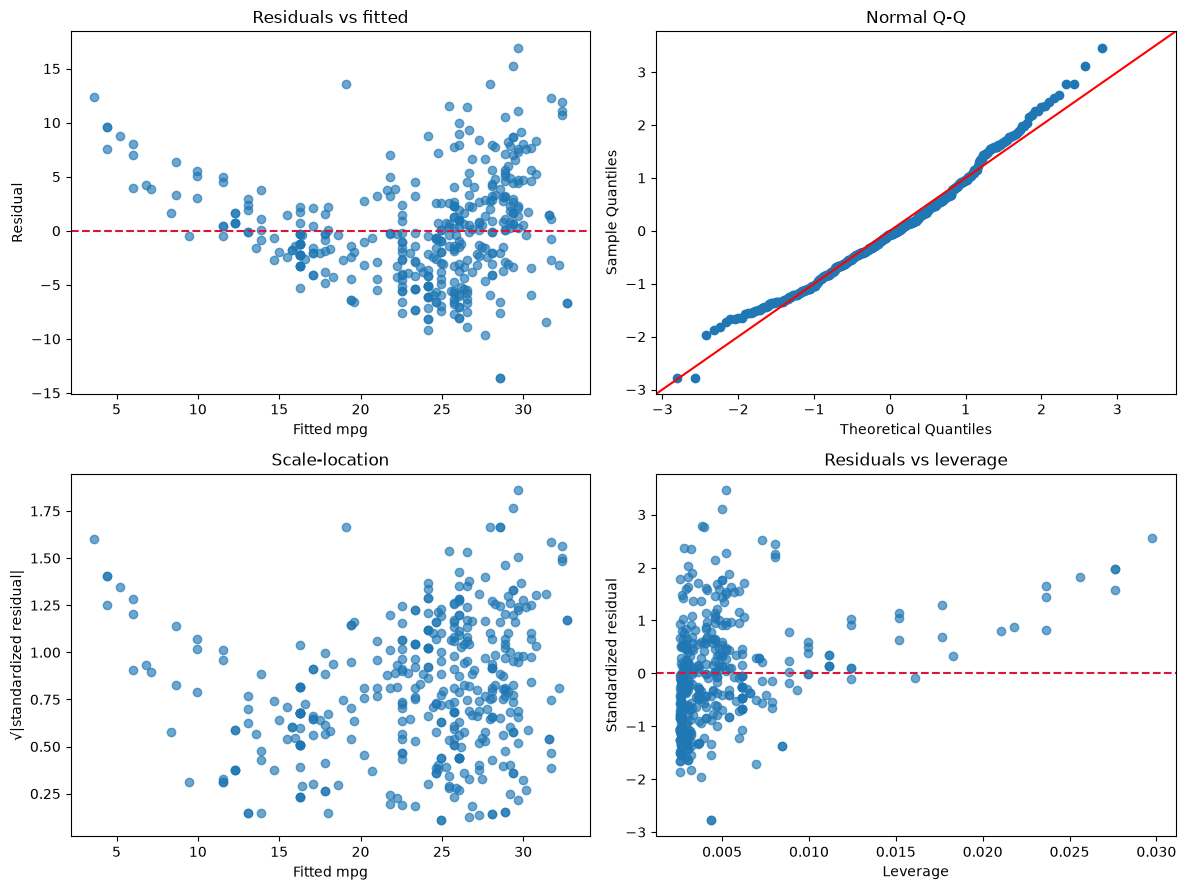

The residual plot shows curvature and some changing spread, so a straight-line model is a useful summary but does not capture every pattern. The Q-Q plot has tail departures. Observations with |studentized residual| > 3: 2; maximum leverage: 0.030.


In [4]:
# Exercise 8(c)
influence_8 = fit_8.get_influence()
standardized_8 = influence_8.resid_studentized_internal
leverage_8 = influence_8.hat_matrix_diag
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].scatter(fit_8.fittedvalues, fit_8.resid, alpha=0.65)
axes[0, 0].axhline(0, color="crimson", linestyle="--")
axes[0, 0].set(title="Residuals vs fitted", xlabel="Fitted mpg", ylabel="Residual")
sm.qqplot(standardized_8, line="45", ax=axes[0, 1])
axes[0, 1].set_title("Normal Q-Q")
axes[1, 0].scatter(fit_8.fittedvalues, np.sqrt(np.abs(standardized_8)), alpha=0.65)
axes[1, 0].set(title="Scale-location", xlabel="Fitted mpg", ylabel="√|standardized residual|")
axes[1, 1].scatter(leverage_8, standardized_8, alpha=0.65)
axes[1, 1].axhline(0, color="crimson", linestyle="--")
axes[1, 1].set(title="Residuals vs leverage", xlabel="Leverage", ylabel="Standardized residual")
plt.tight_layout()
plt.show()
print(
    "The residual plot shows curvature and some changing spread, so a straight-line model "
    "is a useful summary but does not capture every pattern. The Q-Q plot has tail departures. "
    f"Observations with |studentized residual| > 3: {int((np.abs(standardized_8) > 3).sum())}; "
    f"maximum leverage: {leverage_8.max():.3f}."
)

**Observations / conclusions**

- **(a)** There is a strong, **negative** relationship between horsepower and mpg. The slope is −0.158 mpg per horsepower (p < 0.001), and horsepower alone explains 60.6% of the variation in mpg. At **98 hp** the predicted mpg is **24.47**, with a 95% confidence interval of [23.97, 24.96] and a 95% prediction interval of [14.81, 34.12]. The prediction interval is much wider because it also includes the noise of an individual car.
- **(b)** The least-squares line captures the overall downward trend.
- **(c)** The residuals-vs-fitted plot shows clear **curvature** and some change in spread, so the relationship is nonlinear (a quadratic term would help; see Chapter 7). Only 2 observations have |studentized residual| > 3, and no point has unusually high leverage (max 0.03).

---

## Exercise 9 · Applied

**Textbook: printed page 129**

This question involves the use of multiple linear regression on the
Auto data set.

### Exercise 9(a)

Produce a scatterplot matrix which includes all of the variables
in the data set.

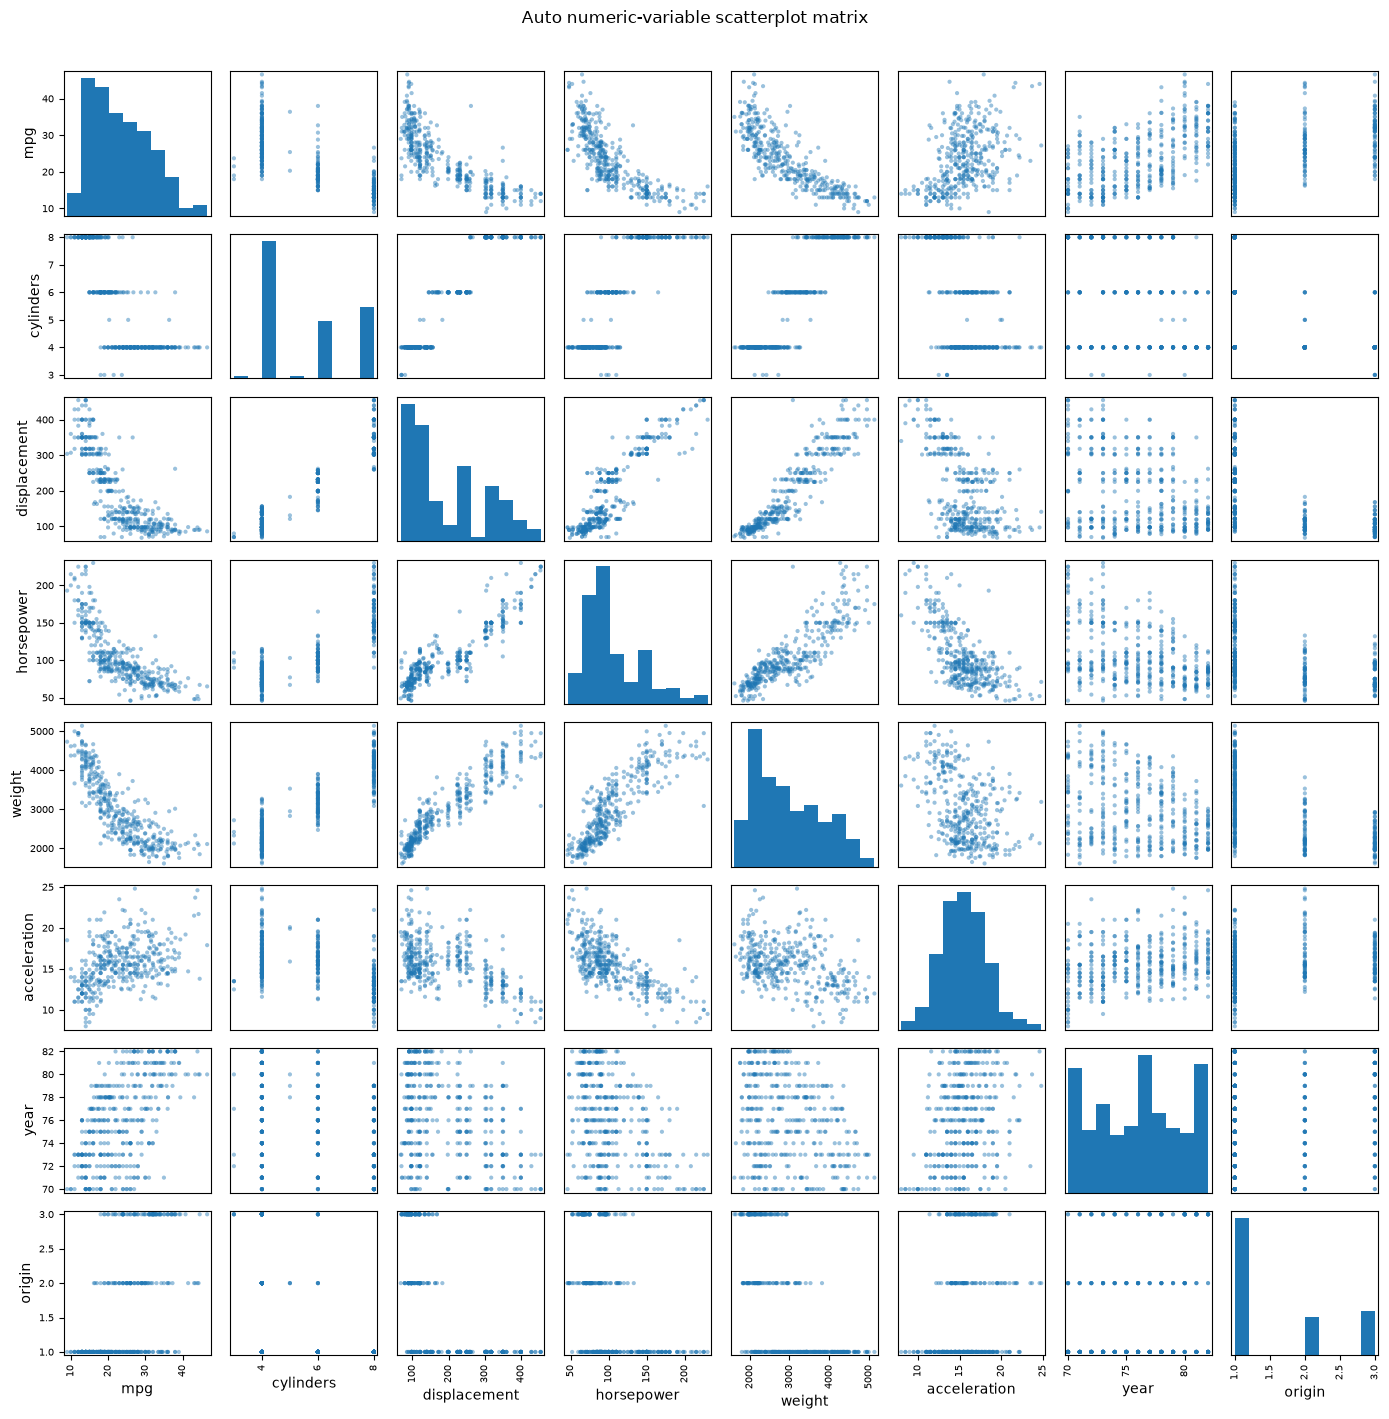

The name field is an identifier rather than a quantitative measurement, so the matrix uses all eight numeric variables.


In [5]:
# Exercise 9(a)
from pandas.plotting import scatter_matrix

numeric_auto = auto.drop(columns="name")
axes = scatter_matrix(numeric_auto, figsize=(14, 14), diagonal="hist", alpha=0.45)
for ax in axes.ravel():
    ax.tick_params(labelsize=7)
plt.suptitle("Auto numeric-variable scatterplot matrix", y=1.01)
plt.tight_layout()
plt.show()
print("The name field is an identifier rather than a quantitative measurement, so the matrix uses all eight numeric variables.")

### Exercise 9(b)

Compute the matrix of correlations between the variables using
the DataFrame.corr() method.
.corr()

In [6]:
# Exercise 9(b)
auto_correlations = numeric_auto.corr()
display(auto_correlations.round(2))

,mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin
mpg,1.00,-0.78,-0.81,-0.78,-0.83,0.42,0.58,0.57
cylinders,-0.78,1.00,0.95,0.84,0.90,-0.50,-0.35,-0.57
displacement,-0.81,0.95,1.00,0.90,0.93,-0.54,-0.37,-0.61
horsepower,-0.78,0.84,0.90,1.00,0.86,-0.69,-0.42,-0.46
weight,-0.83,0.90,0.93,0.86,1.00,-0.42,-0.31,-0.59
acceleration,0.42,-0.50,-0.54,-0.69,-0.42,1.00,0.29,0.21
year,0.58,-0.35,-0.37,-0.42,-0.31,0.29,1.00,0.18
origin,0.57,-0.57,-0.61,-0.46,-0.59,0.21,0.18,1.00


### Exercise 9(c)

Use the sm.OLS() function to perform a multiple linear regression
with mpg as the response and all other variables except name as
the predictors. Use the summarize() function to print the results.
Comment on the output. For instance:
i. Is there a relationship between the predictors and the response? Use the anova_lm() function from statsmodels to
answer this question.
ii. Which predictors appear to have a statistically significant
relationship to the response?
iii. What does the coefficient for the year variable suggest?

In [7]:
# Exercise 9(c)
predictors_9 = [column for column in auto.columns if column not in {"mpg", "name"}]
formula_9 = "mpg ~ " + " + ".join(predictors_9)
fit_9 = smf.ols(formula_9, data=auto).fit()
fit_9_null = smf.ols("mpg ~ 1", data=auto).fit()
print(fit_9.summary())
print("\nOverall nested-model F test (all predictors versus intercept only):")
display(anova_lm(fit_9_null, fit_9).round(4))
significant_9 = fit_9.pvalues.drop("Intercept").loc[lambda p: p < 0.05].index.tolist()
print(f"Predictors significant at 5%: {significant_9}")
print(
    f"The year coefficient is {fit_9.params['year']:.3f}: holding the other included variables fixed, "
    "a one-year increase is associated with this many additional mpg on average."
)

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.821
Model:                            OLS   Adj. R-squared:                  0.818
Method:                 Least Squares   F-statistic:                     252.4
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          2.04e-139
Time:                        19:52:56   Log-Likelihood:                -1023.5
No. Observations:                 392   AIC:                             2063.
Df Residuals:                     384   BIC:                             2095.
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept      -17.2184      4.644     -3.707   

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,391.0,23818.9935,0.0,NaN,NaN,NaN
1,384.0,4252.2125,7.0,19566.7809,252.428,0.0


Predictors significant at 5%: ['displacement', 'weight', 'year', 'origin']
The year coefficient is 0.751: holding the other included variables fixed, a one-year increase is associated with this many additional mpg on average.


### Exercise 9(d)

Produce some of diagnostic plots of the linear regression fit as
described in the lab. Comment on any problems you see with the
fit. Do the residual plots suggest any unusually large outliers?
Does the leverage plot identify any observations with unusually
high leverage?

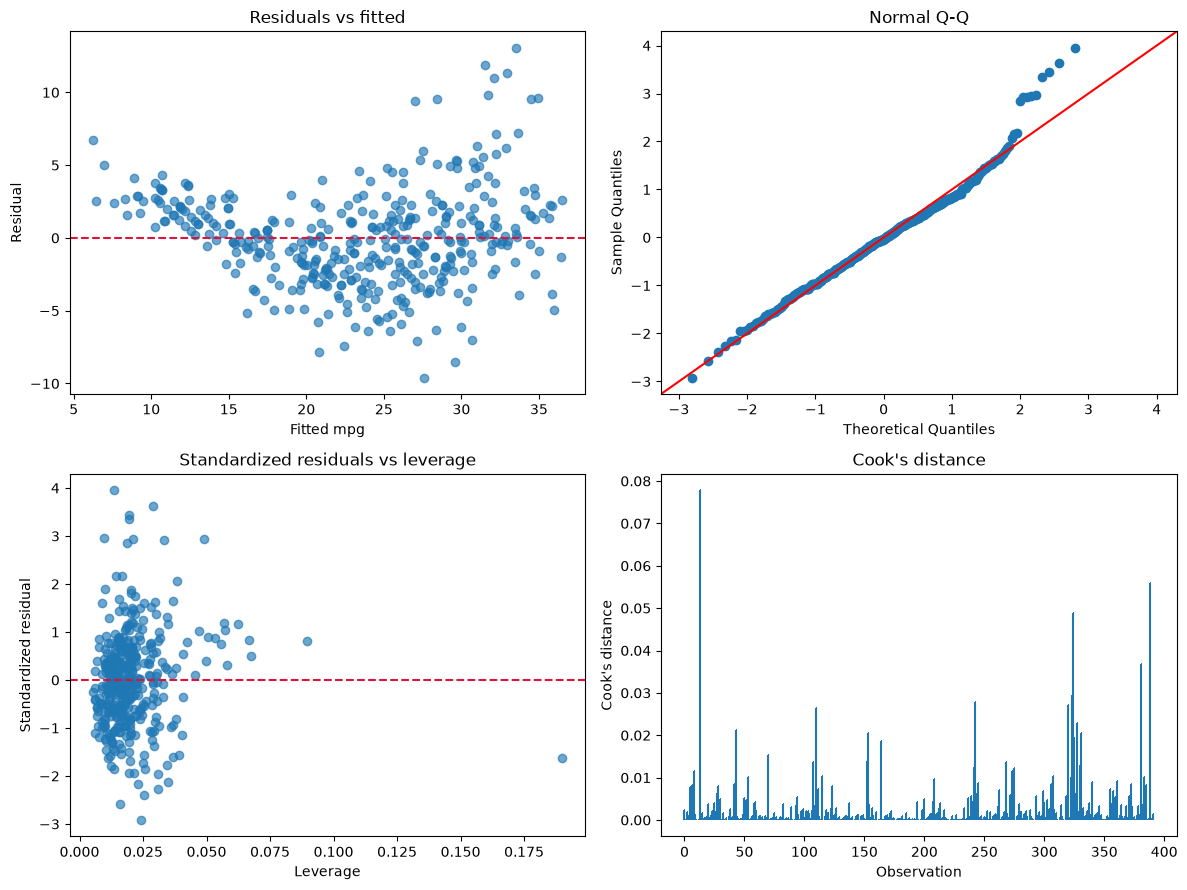

|Internally studentized residual| > 3: observations [243, 321, 324, 325]
Leverage > 2p/n: observations [7, 8, 9, 13, 14, 26, 27, 28, 29, 44, 56, 59, 94, 95, 103, 116, 208, 210, 221, 242, 262, 276, 298, 299, 331, 358, 360, 389]
The diagnostics show some tail departures and influential/high-leverage cases; inspect their Cook's distances alongside the plots.


In [8]:
# Exercise 9(d)
influence_9 = fit_9.get_influence()
standardized_9 = influence_9.resid_studentized_internal
leverage_9 = influence_9.hat_matrix_diag
cooks_9 = influence_9.cooks_distance[0]
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes[0, 0].scatter(fit_9.fittedvalues, fit_9.resid, alpha=0.65)
axes[0, 0].axhline(0, color="crimson", linestyle="--")
axes[0, 0].set(title="Residuals vs fitted", xlabel="Fitted mpg", ylabel="Residual")
sm.qqplot(standardized_9, line="45", ax=axes[0, 1])
axes[0, 1].set_title("Normal Q-Q")
axes[1, 0].scatter(leverage_9, standardized_9, alpha=0.65)
axes[1, 0].axhline(0, color="crimson", linestyle="--")
axes[1, 0].set(title="Standardized residuals vs leverage", xlabel="Leverage", ylabel="Standardized residual")
axes[1, 1].stem(np.arange(len(cooks_9)), cooks_9, markerfmt=",", basefmt=" ")
axes[1, 1].set(title="Cook's distance", xlabel="Observation", ylabel="Cook's distance")
plt.tight_layout()
plt.show()
large_residuals_9 = np.flatnonzero(np.abs(standardized_9) > 3) + 1
high_leverage_9 = np.flatnonzero(leverage_9 > 2 * fit_9.df_model / len(auto)) + 1
print(f"|Internally studentized residual| > 3: observations {large_residuals_9.tolist()}")
print(f"Leverage > 2p/n: observations {high_leverage_9.tolist()}")
print("The diagnostics show some tail departures and influential/high-leverage cases; inspect their Cook's distances alongside the plots.")

### Exercise 9(e)

Fit some models with interactions as described in the lab. Do
any interactions appear to be statistically significant?

In [9]:
# Exercise 9(e)
interaction_formula_9 = (
    "mpg ~ cylinders + displacement + horsepower + weight + acceleration + year + origin "
    "+ horsepower:weight + horsepower:year + weight:year"
)
fit_9_interactions = smf.ols(interaction_formula_9, data=auto).fit()
print(fit_9_interactions.summary())
print("\nNested comparison of the three added interactions:")
display(anova_lm(fit_9, fit_9_interactions).round(4))
print("Individual interaction p-values:")
display(fit_9_interactions.pvalues.filter(like=":").rename("p-value").to_frame().round(4))

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.873
Model:                            OLS   Adj. R-squared:                  0.870
Method:                 Least Squares   F-statistic:                     262.5
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          4.25e-164
Time:                        19:52:57   Log-Likelihood:                -956.32
No. Observations:                 392   AIC:                             1935.
Df Residuals:                     381   BIC:                             1978.
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept           -37.2306     15.32

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,384.0,4252.2125,0.0,NaN,NaN,NaN
1,381.0,3018.6398,3.0,1233.5727,51.8988,0.0


Individual interaction p-values:


,p-value
horsepower:weight,0.0000
horsepower:year,0.0000
weight:year,0.1383


### Exercise 9(f)

Try a few different transformations of the variables, such as
log(X),
√
X, X2. Comment on your findings.

In [10]:
# Exercise 9(f)
transformed_formula_9 = (
    "mpg ~ cylinders + displacement + horsepower + I(horsepower ** 2) + "
    "weight + np.log(weight) + acceleration + year + origin"
)
fit_9_transformed = smf.ols(transformed_formula_9, data=auto).fit()
print(fit_9_transformed.summary())
print("\nLinear versus transformed model comparison (nested terms):")
display(anova_lm(fit_9, fit_9_transformed).round(4))
print(f"Baseline AIC={fit_9.aic:.1f}; transformed-model AIC={fit_9_transformed.aic:.1f}.")
print("The squared-horsepower and log-weight terms allow curvature; use their p-values and the model comparison to judge whether they improve the fit.")

                            OLS Regression Results                            
Dep. Variable:                    mpg   R-squared:                       0.863
Model:                            OLS   Adj. R-squared:                  0.860
Method:                 Least Squares   F-statistic:                     267.6
Date:                Tue, 27 Oct 2026   Prob (F-statistic):          5.84e-159
Time:                        19:52:57   Log-Likelihood:                -971.44
No. Observations:                 392   AIC:                             1963.
Df Residuals:                     382   BIC:                             2003.
Df Model:                           9                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept            170.0957     36

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,384.0,4252.2125,0.0,NaN,NaN,NaN
1,382.0,3260.8124,2.0,991.4001,58.0706,0.0


Baseline AIC=2062.9; transformed-model AIC=1962.9.
The squared-horsepower and log-weight terms allow curvature; use their p-values and the model comparison to judge whether they improve the fit.


**Observations / conclusions**

- **(a, b)** The scatterplot matrix and correlations show mpg is strongly negatively correlated with weight (−0.83), displacement (−0.81), horsepower and cylinders (−0.78). These four predictors are also highly correlated with each other (0.84–0.95), which is a collinearity warning.
- **(c)** The multiple regression is highly significant overall (F = 252, p ≈ 0) with $R^2 = 0.82$. Holding the others fixed, **displacement, weight, year and origin** are significant. Cylinders, horsepower and acceleration are not, once the other variables are in the model. The **year** coefficient (0.75) means that cars one model-year newer get about 0.75 mpg more on average, all else equal.
- **(d)** The diagnostic plots again show some curvature and heavier-than-normal tails. There are 4 outliers (observations 243, 321, 324, 325 with |studentized residual| > 3), and 28 observations exceed the 2p/n leverage rule of thumb. The largest Cook's distance is only 0.078, so no single car is strongly influential.
- **(e)** Interactions help. `horsepower:weight` and `horsepower:year` are highly significant; `weight:year` is not (p = 0.14). $R^2$ rises to 0.87.
- **(f)** Transformations also help. With $\text{horsepower}^2$ and $\log(\text{weight})$ both significant, AIC drops from 2063 to 1963. This confirms the nonlinearity seen in the residual plots.

---

## Exercise 10 · Applied

**Textbook: printed page 130**

This question should be answered using the Carseats data set.

### Exercise 10(a)

Fit a multiple regression model to predict Sales using Price,
Urban, and US.

In [11]:
# Exercise 10(a)
fit_10a = smf.ols("Sales ~ Price + Urban + US", data=carseats).fit()
print(fit_10a.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.239
Model:                            OLS   Adj. R-squared:                  0.234
Method:                 Least Squares   F-statistic:                     41.52
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           2.39e-23
Time:                        19:52:57   Log-Likelihood:                -927.66
No. Observations:                 400   AIC:                             1863.
Df Residuals:                     396   BIC:                             1879.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
Intercept       13.0435      0.651     20.036   

### Exercise 10(b)

Provide an interpretation of each coefficient in the model. Be
careful—some of the variables in the model are qualitative!

In [12]:
# Exercise 10(b)
print("With Urban=No and US=No as reference levels, holding other predictors fixed:")
print(f"• Price: a one-dollar increase in price changes expected Sales by {fit_10a.params['Price']:.3f} thousand units.")
print(f"• Urban=Yes: expected Sales differs by {fit_10a.params['Urban[T.Yes]']:.3f} thousand units from Urban=No.")
print(f"• US=Yes: expected Sales differs by {fit_10a.params['US[T.Yes]']:.3f} thousand units from US=No.")
print(f"• Intercept ({fit_10a.params['Intercept']:.3f}): expected Sales for a non-US store in a non-urban location at Price=0; this is a mathematical baseline, not a realistic price.")

With Urban=No and US=No as reference levels, holding other predictors fixed:
• Price: a one-dollar increase in price changes expected Sales by -0.054 thousand units.
• Urban=Yes: expected Sales differs by -0.022 thousand units from Urban=No.
• US=Yes: expected Sales differs by 1.201 thousand units from US=No.
• Intercept (13.043): expected Sales for a non-US store in a non-urban location at Price=0; this is a mathematical baseline, not a realistic price.


### Exercise 10(c)

Write out the model in equation form, being careful to handle
the qualitative variables properly.

In [13]:
# Exercise 10(c)
print(
    "Using indicator variables U=1 for Urban=Yes and S=1 for US=Yes, the fitted model is:\n"
    f"Sales_hat = {fit_10a.params['Intercept']:.3f} "
    f"{fit_10a.params['Price']:+.3f} Price "
    f"{fit_10a.params['Urban[T.Yes]']:+.3f} U "
    f"{fit_10a.params['US[T.Yes]']:+.3f} S."
)
print("Each indicator is 0 for its reference category (No).")

Using indicator variables U=1 for Urban=Yes and S=1 for US=Yes, the fitted model is:
Sales_hat = 13.043 -0.054 Price -0.022 U +1.201 S.
Each indicator is 0 for its reference category (No).


### Exercise 10(d)

For which of the predictors can you reject the null hypothesis
H0 : βj = 0?

In [14]:
# Exercise 10(d)
pvalues_10 = fit_10a.pvalues.drop("Intercept")
display(pvalues_10.rename("p-value").to_frame().round(5))
reject_10 = pvalues_10[pvalues_10 < 0.05].index.tolist()
print(f"At the 5% level, reject H0 for: {reject_10}.")

,p-value
Urban[T.Yes],0.93574
US[T.Yes],0.00000
Price,0.00000


At the 5% level, reject H0 for: ['US[T.Yes]', 'Price'].


### Exercise 10(e)

On the basis of your response to the previous question, fit a
smaller model that only uses the predictors for which there is
evidence of association with the outcome.

In [15]:
# Exercise 10(e)
selected_terms_10 = ["Price"]
if any(term.startswith("US[") for term in reject_10):
    selected_terms_10.append("US")
formula_10e = "Sales ~ " + " + ".join(selected_terms_10)
fit_10e = smf.ols(formula_10e, data=carseats).fit()
print(f"Reduced-model formula: {formula_10e}")
print(fit_10e.summary())

Reduced-model formula: Sales ~ Price + US
                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.239
Model:                            OLS   Adj. R-squared:                  0.235
Method:                 Least Squares   F-statistic:                     62.43
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           2.66e-24
Time:                        19:52:57   Log-Likelihood:                -927.66
No. Observations:                 400   AIC:                             1861.
Df Residuals:                     397   BIC:                             1873.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept 

### Exercise 10(f)

How well do the models in (a) and (e) fit the data?

In [16]:
# Exercise 10(f)
fit_metrics_10 = pd.DataFrame(
    {
        "R-squared": [fit_10a.rsquared, fit_10e.rsquared],
        "Adjusted R-squared": [fit_10a.rsquared_adj, fit_10e.rsquared_adj],
        "Residual standard error": [np.sqrt(fit_10a.mse_resid), np.sqrt(fit_10e.mse_resid)],
    },
    index=["Model (a): Price + Urban + US", "Model (e): " + " + ".join(selected_terms_10)],
)
display(fit_metrics_10.round(4))
print("Both models explain some variation in Sales; the reduced model is more parsimonious, and its fit can be compared with the full model using adjusted R-squared and residual standard error.")

,R-squared,Adjusted R-squared,Residual standard error
Model (a): Price + Urban + US,0.2393,0.2335,2.4725
Model (e): Price + US,0.2393,0.2354,2.4694


Both models explain some variation in Sales; the reduced model is more parsimonious, and its fit can be compared with the full model using adjusted R-squared and residual standard error.


### Exercise 10(g)

Using the model from (e), obtain 95 % confidence intervals for
the coefficient(s).

In [17]:
# Exercise 10(g)
print("95% confidence intervals for the reduced-model coefficients:")
display(fit_10e.conf_int(alpha=0.05).rename(columns={0: "Lower 95%", 1: "Upper 95%"}).round(4))

95% confidence intervals for the reduced-model coefficients:


,Lower 95%,Upper 95%
Intercept,11.7903,14.2713
US[T.Yes],0.6915,1.7078
Price,-0.0648,-0.0442


### Exercise 10(h)

Is there evidence of outliers or high leverage observations in the
model from (e)?

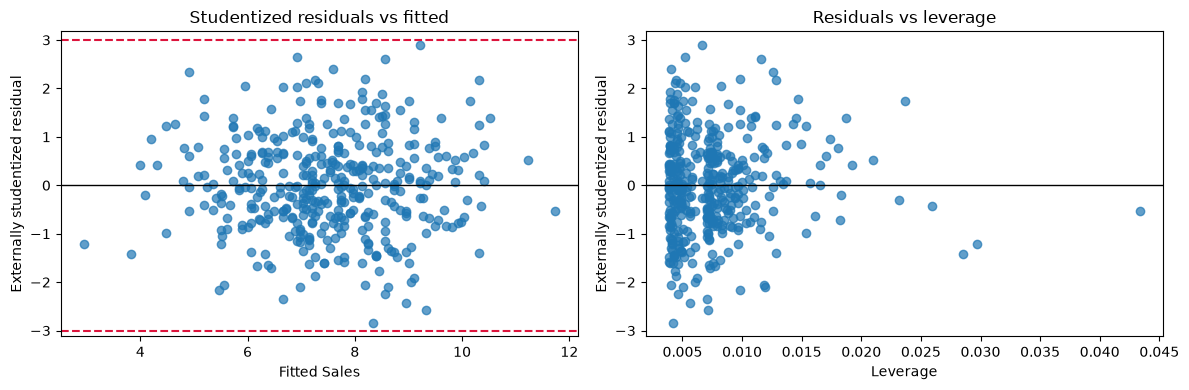

Observations with |studentized residual| > 3: 0.
Maximum leverage=0.043 (2p/n threshold=0.015); maximum Cook's distance=0.026.


In [18]:
# Exercise 10(h)
influence_10e = fit_10e.get_influence()
studentized_10e = influence_10e.resid_studentized_external
leverage_10e = influence_10e.hat_matrix_diag
cooks_10e = influence_10e.cooks_distance[0]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(fit_10e.fittedvalues, studentized_10e, alpha=0.7)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].axhline(3, color="crimson", linestyle="--")
axes[0].axhline(-3, color="crimson", linestyle="--")
axes[0].set(title="Studentized residuals vs fitted", xlabel="Fitted Sales", ylabel="Externally studentized residual")
axes[1].scatter(leverage_10e, studentized_10e, alpha=0.7)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(title="Residuals vs leverage", xlabel="Leverage", ylabel="Externally studentized residual")
plt.tight_layout()
plt.show()
print(f"Observations with |studentized residual| > 3: {int((np.abs(studentized_10e) > 3).sum())}.")
print(f"Maximum leverage={leverage_10e.max():.3f} (2p/n threshold={2 * len(fit_10e.params) / len(carseats):.3f}); maximum Cook's distance={cooks_10e.max():.3f}.")

**Observations / conclusions**

- **(a–c)** Model: $\widehat{\text{Sales}} = 13.04 - 0.054\,\text{Price} - 0.022\,\text{Urban} + 1.20\,\text{US}$. Each \$1 increase in price lowers expected sales by about 54 units. US stores sell about 1,200 more units than non-US stores. Urban vs rural makes essentially no difference.
- **(d)** We can reject $H_0: \beta_j = 0$ for **Price** and **US** (p < 0.001), but not for Urban (p = 0.94).
- **(e, f)** The reduced model `Sales ~ Price + US` fits as well as the full one: $R^2 = 0.239$ in both, adjusted $R^2$ 0.235 vs 0.234, and RSE 2.469 vs 2.473. Both explain only about 24% of the variation in sales.
- **(g)** 95% CIs: Price [−0.065, −0.044] and US [0.69, 1.71]. Neither includes zero.
- **(h)** There are no outliers (no |studentized residual| > 3). Several points have leverage above the 2p/n rule of thumb (max 0.043), but all have small Cook's distance (max 0.026), so none is influential.

---

## Exercise 11 · Applied

**Textbook: printed page 130**

In this problem we will investigate the t-statistic for the null hypothesis H0 : β = 0 in simple linear regression without an intercept. To
begin, we generate a predictor x and a response y as follows.
rng = np.random.default_rng(1)
x = rng.normal(size=100)
y = 2 * x + rng.normal(size=100)

### Exercise 11(a)

Perform a simple linear regression of y onto x, without an intercept. Report the coefficient estimate ˆβ, the standard error of
this coefficient estimate, and the t-statistic and p-value associated with the null hypothesis H0 : β = 0. Comment on these
results. (You can perform regression without an intercept using
the keywords argument intercept=False to ModelSpec().)

In [19]:
# Exercise 11(a)
rng_11 = np.random.default_rng(1)
x_11 = rng_11.normal(size=100)
y_11 = 2 * x_11 + rng_11.normal(size=100)
fit_11_yx = sm.OLS(y_11, x_11).fit()  # no intercept
print(fit_11_yx.summary())
print(
    f"Estimate={fit_11_yx.params[0]:.4f}; standard error={fit_11_yx.bse[0]:.4f}; "
    f"t={fit_11_yx.tvalues[0]:.4f}; p={fit_11_yx.pvalues[0]:.3g}."
)

                                 OLS Regression Results                                
Dep. Variable:                      y   R-squared (uncentered):                   0.743
Model:                            OLS   Adj. R-squared (uncentered):              0.740
Method:                 Least Squares   F-statistic:                              285.6
Date:                Tue, 27 Oct 2026   Prob (F-statistic):                    6.23e-31
Time:                        19:52:57   Log-Likelihood:                         -141.35
No. Observations:                 100   AIC:                                      284.7
Df Residuals:                      99   BIC:                                      287.3
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

### Exercise 11(b)

Now perform a simple linear regression of x onto y without an
intercept, and report the coefficient estimate, its standard error,
and the corresponding t-statistic and p-values associated with
the null hypothesis H0 : β = 0. Comment on these results.

In [20]:
# Exercise 11(b)
fit_11_xy = sm.OLS(x_11, y_11).fit()  # no intercept
print(fit_11_xy.summary())
print(
    f"Estimate={fit_11_xy.params[0]:.4f}; standard error={fit_11_xy.bse[0]:.4f}; "
    f"t={fit_11_xy.tvalues[0]:.4f}; p={fit_11_xy.pvalues[0]:.3g}."
)

                                 OLS Regression Results                                
Dep. Variable:                      y   R-squared (uncentered):                   0.743
Model:                            OLS   Adj. R-squared (uncentered):              0.740
Method:                 Least Squares   F-statistic:                              285.6
Date:                Tue, 27 Oct 2026   Prob (F-statistic):                    6.23e-31
Time:                        19:52:57   Log-Likelihood:                         -58.349
No. Observations:                 100   AIC:                                      118.7
Df Residuals:                      99   BIC:                                      121.3
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

### Exercise 11(c)

Compare the results from (a) and (b). How do the coefficient estimates and their standard errors differ, and what do you notice about the t-statistics?

In [21]:
# Exercise 11(c)
print(
    f"The fitted slopes differ ({fit_11_yx.params[0]:.4f} versus {fit_11_xy.params[0]:.4f}), "
    f"and their standard errors differ ({fit_11_yx.bse[0]:.4f} versus {fit_11_xy.bse[0]:.4f}). "
    f"However, the t-statistics are equal: {fit_11_yx.tvalues[0]:.6f} and {fit_11_xy.tvalues[0]:.6f}. "
    "Both test the same zero-correlation/no-linear-association condition in these no-intercept regressions."
)

The fitted slopes differ (1.9762 versus 0.3757), and their standard errors differ (0.1169 versus 0.0222). However, the t-statistics are equal: 16.898417 and 16.898417. Both test the same zero-correlation/no-linear-association condition in these no-intercept regressions.


### Numerical check for Exercise 11(c)

The t-statistics from the two regressions should match; the next cell verifies this equality numerically.

In [22]:
# Exercise 11: numerical symmetry check (the source worksheet has an incomplete follow-up prompt here)
print(f"|t(y on x) - t(x on y)| = {abs(fit_11_yx.tvalues[0] - fit_11_xy.tvalues[0]):.3e}")
assert np.isclose(fit_11_yx.tvalues[0], fit_11_xy.tvalues[0])

|t(y on x) - t(x on y)| = 0.000e+00


### Exercise 11(d)

For the regression of $Y$ on $X$ through the origin,

$$
\hat\beta = \frac{\sum_i x_i y_i}{\sum_i x_i^2}, \qquad
SE(\hat\beta) = \sqrt{\frac{\sum_i (y_i - x_i\hat\beta)^2}{(n-1)\sum_i x_i^2}}.
$$

Show algebraically, then verify numerically, that the t-statistic can be written as

$$
t = \frac{\sqrt{n-1}\sum_i x_i y_i}{\sqrt{(\sum_i x_i^2)(\sum_i y_i^2) - (\sum_i x_i y_i)^2}}.
$$

In [23]:
# Exercise 11(d)
from IPython.display import Markdown, display

sum_xy = np.sum(x_11 * y_11)
sum_x2 = np.sum(x_11**2)
sum_y2 = np.sum(y_11**2)
beta_no_intercept = sum_xy / sum_x2
se_no_intercept = np.sqrt(np.sum((y_11 - beta_no_intercept * x_11) ** 2) / ((len(x_11) - 1) * sum_x2))
t_from_definition = beta_no_intercept / se_no_intercept
t_from_symmetric_form = np.sqrt(len(x_11) - 1) * sum_xy / np.sqrt(sum_x2 * sum_y2 - sum_xy**2)

display(Markdown(r"""
For a regression through the origin,
$$\hat\beta=\frac{\sum_i x_i y_i}{\sum_i x_i^2},\qquad
\mathrm{SSE}=\sum_i y_i^2-\frac{(\sum_i x_i y_i)^2}{\sum_i x_i^2}.$$
Using $SE(\hat\beta)=\sqrt{\mathrm{SSE}/((n-1)\sum_i x_i^2)}$ and simplifying gives
$$t=\frac{\sqrt{n-1}\sum_i x_i y_i}{\sqrt{(\sum_i x_i^2)(\sum_i y_i^2)-(\sum_i x_i y_i)^2}}.$$
"""))
print(f"t from coefficient / standard error = {t_from_definition:.10f}")
print(f"t from the symmetric expression       = {t_from_symmetric_form:.10f}")
print(f"Absolute numerical difference          = {abs(t_from_definition - t_from_symmetric_form):.3e}")
assert np.isclose(t_from_definition, t_from_symmetric_form)


For a regression through the origin,
$$\hat\beta=\frac{\sum_i x_i y_i}{\sum_i x_i^2},\qquad
\mathrm{SSE}=\sum_i y_i^2-\frac{(\sum_i x_i y_i)^2}{\sum_i x_i^2}.$$
Using $SE(\hat\beta)=\sqrt{\mathrm{SSE}/((n-1)\sum_i x_i^2)}$ and simplifying gives
$$t=\frac{\sqrt{n-1}\sum_i x_i y_i}{\sqrt{(\sum_i x_i^2)(\sum_i y_i^2)-(\sum_i x_i y_i)^2}}.$$


t from coefficient / standard error = 16.8984170630
t from the symmetric expression       = 16.8984170630
Absolute numerical difference          = 7.105e-15


### Exercise 11(e)

Using the results from (d), argue that the t-statistic for the regression of y onto x is the same as the t-statistic for the regression
of x onto y.

In [24]:
# Exercise 11(e)
print(
    "The expression derived in (d) is symmetric in x and y: swapping them leaves Σxᵢyᵢ, "
    "Σxᵢ²Σyᵢ², and n unchanged. Therefore the two through-origin slope tests have the same t-statistic. "
    f"Numerically, t(y on x)={fit_11_yx.tvalues[0]:.6f} and t(x on y)={fit_11_xy.tvalues[0]:.6f}."
)

The expression derived in (d) is symmetric in x and y: swapping them leaves Σxᵢyᵢ, Σxᵢ²Σyᵢ², and n unchanged. Therefore the two through-origin slope tests have the same t-statistic. Numerically, t(y on x)=16.898417 and t(x on y)=16.898417.


### Exercise 11(f)

In R, show that when regression is performed with an intercept,
the t-statistic for H0 : β1 = 0 is the same for the regression of y
onto x as it is for the regression of x onto y.

In [25]:
# Exercise 11(f)
fit_11_yx_intercept = sm.OLS(y_11, sm.add_constant(x_11)).fit()
fit_11_xy_intercept = sm.OLS(x_11, sm.add_constant(y_11)).fit()
t_yx_intercept = fit_11_yx_intercept.tvalues[1]
t_xy_intercept = fit_11_xy_intercept.tvalues[1]
print(f"With intercept: t(y on x)={t_yx_intercept:.10f}; t(x on y)={t_xy_intercept:.10f}.")
print(f"Absolute difference={abs(t_yx_intercept - t_xy_intercept):.3e}.")
assert np.isclose(t_yx_intercept, t_xy_intercept)
print("The t-statistics are identical because each equals the sample correlation scaled by the same degrees-of-freedom factor.")

With intercept: t(y on x)=16.7340552024; t(x on y)=16.7340552024.
Absolute difference=7.105e-15.
The t-statistics are identical because each equals the sample correlation scaled by the same degrees-of-freedom factor.


**Observations / conclusions**

- **(a)** Regressing y on x without an intercept gives $\hat\beta = 1.976$ (SE 0.117, t = 16.9, p ≈ 6e-31), close to the true value 2. We reject $H_0: \beta = 0$.
- **(b)** Regressing x on y gives $\hat\beta = 0.376$ (SE 0.022), but **the same t = 16.9**.
- **(c)** The two slopes are not reciprocals (1/1.976 ≈ 0.51 ≠ 0.376) because each regression minimises error in a different direction. Yet both test the same thing: whether x and y are linearly related.
- **(d, e)** The t-statistic can be written as $t = \frac{\sqrt{n-1}\,\sum x_iy_i}{\sqrt{\sum x_i^2\sum y_i^2 - (\sum x_iy_i)^2}}$. This is symmetric in x and y, so swapping them leaves t unchanged; the numerical check agrees to 1e-14.
- **(f)** The same holds *with* an intercept: t = 16.734 for both directions, because in simple regression with an intercept, t depends only on the sample correlation and n.

---

## Exercise 12 · Applied

**Textbook: printed page 131**

This problem involves simple linear regression without an intercept.

### Exercise 12(a)

Recall that the coefficient estimate ˆβ for the linear regression of
Y onto X without an intercept is given by (3.38). Under what
circumstance is the coefficient estimate for the regression of X
onto Y the same as the coefficient estimate for the regression of
Y onto X?

In [26]:
# Exercise 12(a)
print(
    "For no-intercept regressions, b_(Y on X)=ΣXY/ΣX² and b_(X on Y)=ΣXY/ΣY². "
    "They are equal whenever ΣX²=ΣY² (equal sums of squares); they are also both zero if ΣXY=0."
)

For no-intercept regressions, b_(Y on X)=ΣXY/ΣX² and b_(X on Y)=ΣXY/ΣY². They are equal whenever ΣX²=ΣY² (equal sums of squares); they are also both zero if ΣXY=0.


### Exercise 12(b)

Generate an example in Python with n = 100 observations in
which the coefficient estimate for the regression of X onto Y
is different from the coefficient estimate for the regression of Y
onto X.

In [27]:
# Exercise 12(b)
rng_12b = np.random.default_rng(12)
x_12b = rng_12b.normal(size=100)
y_12b = 1.5 * x_12b + rng_12b.normal(scale=0.8, size=100)
beta_y_on_x_12b = np.dot(x_12b, y_12b) / np.dot(x_12b, x_12b)
beta_x_on_y_12b = np.dot(x_12b, y_12b) / np.dot(y_12b, y_12b)
print(f"No-intercept slope for Y on X: {beta_y_on_x_12b:.4f}")
print(f"No-intercept slope for X on Y: {beta_x_on_y_12b:.4f}")
print(f"These differ because ΣX²={np.dot(x_12b, x_12b):.2f} is not ΣY²={np.dot(y_12b, y_12b):.2f}.")

No-intercept slope for Y on X: 1.4407
No-intercept slope for X on Y: 0.5153
These differ because ΣX²=83.41 is not ΣY²=233.20.


### Exercise 12(c)

Generate an example in Python with n = 100 observations in
which the coefficient estimate for the regression of X onto Y is
the same as the coefficient estimate for the regression of Y onto
X.

In [28]:
# Exercise 12(c)
rng_12c = np.random.default_rng(13)
x_12c = rng_12c.normal(size=100)
y_12c = rng_12c.normal(size=100)
y_12c *= np.linalg.norm(x_12c) / np.linalg.norm(y_12c)  # match sums of squares exactly
beta_y_on_x_12c = np.dot(x_12c, y_12c) / np.dot(x_12c, x_12c)
beta_x_on_y_12c = np.dot(x_12c, y_12c) / np.dot(y_12c, y_12c)
print(f"ΣX²={np.dot(x_12c, x_12c):.8f}; ΣY²={np.dot(y_12c, y_12c):.8f}")
print(f"No-intercept slopes: Y on X={beta_y_on_x_12c:.6f}; X on Y={beta_x_on_y_12c:.6f}.")

ΣX²=99.97737566; ΣY²=99.97737566
No-intercept slopes: Y on X=0.027865; X on Y=0.027865.


**Observations / conclusions**

- **(a)** For regression through the origin, $\hat\beta_{Y\sim X} = \sum x_iy_i / \sum x_i^2$ and $\hat\beta_{X\sim Y} = \sum x_iy_i / \sum y_i^2$. They are equal exactly when $\sum x_i^2 = \sum y_i^2$.
- **(b)** In my example the two slopes are different (1.441 vs 0.515) because $\sum x^2 = 83.4 \neq \sum y^2 = 233.2$.
- **(c)** When y is rescaled so that $\sum y^2 = \sum x^2$ (both 99.98), the two slopes are identical (0.0279), even though x and y are different vectors.

---

## Exercise 13 · Applied

**Textbook: printed page 131**

In this exercise you will create some simulated data and will fit simple
linear regression models to it. Make sure to use the default random
number generator with seed set to 1 prior to starting part (a) to
ensure consistent results.

### Exercise 13(a)

Using the normal() method of your random number generator,
create a vector, x, containing 100 observations drawn from a
N(0, 1) distribution. This represents a feature, X.

In [29]:
# Exercise 13(a)
rng_13 = np.random.default_rng(1)
x_13 = rng_13.normal(size=100)
print(f"Created x with shape {x_13.shape}; sample mean={x_13.mean():.3f}, sample variance={x_13.var(ddof=1):.3f}.")

Created x with shape (100,); sample mean=-0.074, sample variance=0.732.


### Exercise 13(b)

Using the normal() method, create a vector, eps, containing 100
observations drawn from a N(0, 0.25) distribution—a normal
distribution with mean zero and variance 0.25.

In [30]:
# Exercise 13(b)
eps_13 = rng_13.normal(loc=0, scale=np.sqrt(0.25), size=100)
print(f"Created eps with shape {eps_13.shape}; requested variance=0.25, sample variance={eps_13.var(ddof=1):.3f}.")

Created eps with shape (100,); requested variance=0.25, sample variance=0.249.


### Exercise 13(c)

Using x and eps, generate a vector y according to the model
Y = −1 + 0.5X + ϵ.
(3.39)
What is the length of the vector y? What are the values of β0
and β1 in this linear model?

In [31]:
# Exercise 13(c)
beta0_13, beta1_13 = -1, 0.5
y_13 = beta0_13 + beta1_13 * x_13 + eps_13
print(f"Length of y: {len(y_13)}")
print(f"Population coefficients: β0={beta0_13}, β1={beta1_13}.")

Length of y: 100
Population coefficients: β0=-1, β1=0.5.


### Exercise 13(d)

Create a scatterplot displaying the relationship between x and
y. Comment on what you observe.

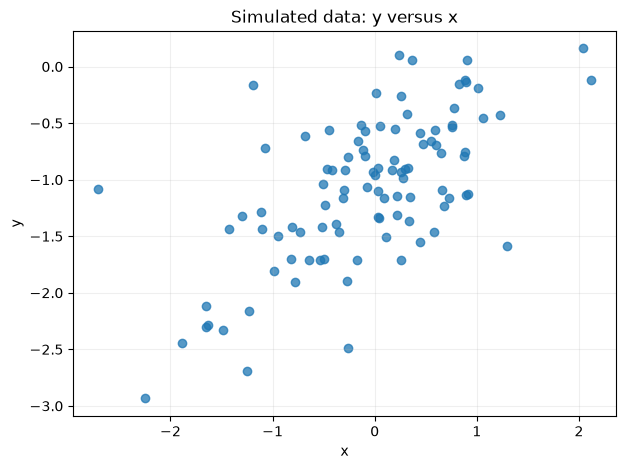

The points follow an upward, approximately linear pattern around the population line y = −1 + 0.5x, with vertical scatter from the noise.


In [32]:
# Exercise 13(d)
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x_13, y_13, alpha=0.75)
ax.set(title="Simulated data: y versus x", xlabel="x", ylabel="y")
ax.grid(alpha=0.2)
plt.show()
print("The points follow an upward, approximately linear pattern around the population line y = −1 + 0.5x, with vertical scatter from the noise.")

### Exercise 13(e)

Fit a least squares linear model to predict y using x. Comment
on the model obtained. How do ˆβ0 and ˆβ1 compare to β0 and
β1?

In [33]:
# Exercise 13(e)
fit_13 = smf.ols("y ~ x", data=pd.DataFrame({"x": x_13, "y": y_13})).fit()
print(fit_13.summary())
print(f"True (β0, β1)=({beta0_13:.2f}, {beta1_13:.2f}); estimated (β̂0, β̂1)=({fit_13.params['Intercept']:.3f}, {fit_13.params['x']:.3f}).")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.409
Model:                            OLS   Adj. R-squared:                  0.403
Method:                 Least Squares   F-statistic:                     67.79
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           8.04e-13
Time:                        19:52:57   Log-Likelihood:                -71.745
No. Observations:                 100   AIC:                             147.5
Df Residuals:                      98   BIC:                             152.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.0380      0.050    -20.647      0.0

### Exercise 13(f)

Display the least squares line on the scatterplot obtained in (d).
Draw the population regression line on the plot, in a different
color. Use the legend() method of the axes to create an appropriate legend.

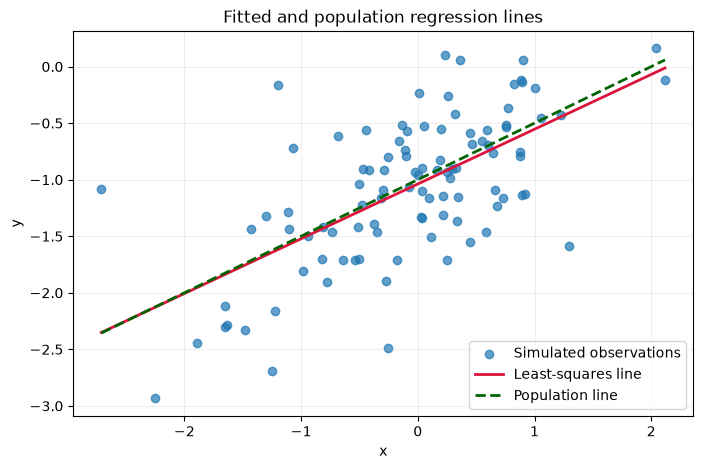

In [34]:
# Exercise 13(f)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x_13, y_13, alpha=0.7, label="Simulated observations")
x_grid_13 = np.linspace(x_13.min(), x_13.max(), 200)
ax.plot(x_grid_13, fit_13.params["Intercept"] + fit_13.params["x"] * x_grid_13, color="crimson", linewidth=2, label="Least-squares line")
ax.plot(x_grid_13, beta0_13 + beta1_13 * x_grid_13, color="darkgreen", linestyle="--", linewidth=2, label="Population line")
ax.set(title="Fitted and population regression lines", xlabel="x", ylabel="y")
ax.legend()
ax.grid(alpha=0.2)
plt.show()

### Exercise 13(g)

Now fit a polynomial regression model that predicts y using x
and x2. Is there evidence that the quadratic term improves the
model fit? Explain your answer.

In [35]:
# Exercise 13(g)
fit_13_quad = smf.ols("y ~ x + I(x ** 2)", data=pd.DataFrame({"x": x_13, "y": y_13})).fit()
print(fit_13_quad.summary())
print("Nested-model test for the added quadratic term:")
display(anova_lm(fit_13, fit_13_quad).round(4))
print(f"The quadratic-term p-value is {fit_13_quad.pvalues['I(x ** 2)']:.4f}; at 5%, there is not compelling evidence that curvature improves this linear population model.")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.409
Model:                            OLS   Adj. R-squared:                  0.397
Method:                 Least Squares   F-statistic:                     33.55
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           8.42e-12
Time:                        19:52:57   Log-Likelihood:                -71.744
No. Observations:                 100   AIC:                             149.5
Df Residuals:                      97   BIC:                             157.3
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.0364      0.060    -17.399      0.0

,df_resid,ssr,df_diff,ss_diff,F,Pr(>F)
0,98.0,24.5866,0.0,NaN,NaN,NaN
1,97.0,24.5859,1.0,0.0007,0.0027,0.9588


The quadratic-term p-value is 0.9588; at 5%, there is not compelling evidence that curvature improves this linear population model.


### Exercise 13(h)

Repeat (a)–(f) after modifying the data generation process in
such a way that there is less noise in the data. The model (3.39)
should remain the same. You can do this by decreasing the variance of the normal distribution used to generate the error term
ϵ in (b). Describe your results.

Low-noise sample variance=0.0497; n=100.
Estimated coefficients: intercept=-1.0170, slope=0.4930; R²=0.7818.


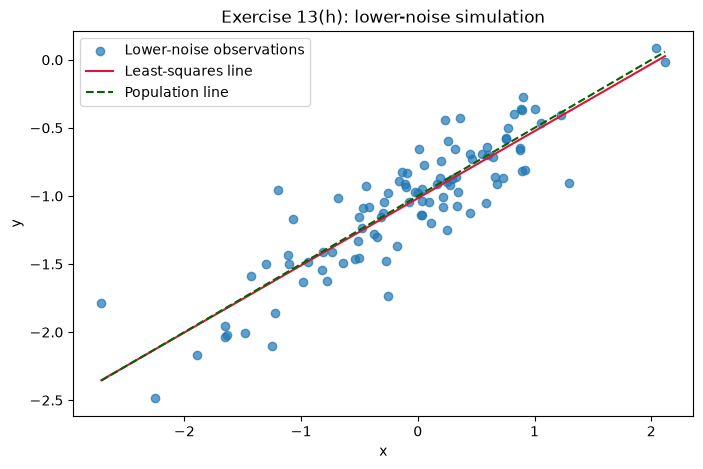

With less noise, observations cluster more tightly around the population line and the fitted coefficients are closer to their true values.


In [36]:
# Exercise 13(h)
rng_13_low = np.random.default_rng(1)
x_13_low = rng_13_low.normal(size=100)
eps_13_low = rng_13_low.normal(loc=0, scale=np.sqrt(0.05), size=100)  # lower variance than 0.25
y_13_low = -1 + 0.5 * x_13_low + eps_13_low
fit_13_low = smf.ols("y ~ x", data=pd.DataFrame({"x": x_13_low, "y": y_13_low})).fit()
print(f"Low-noise sample variance={eps_13_low.var(ddof=1):.4f}; n={len(y_13_low)}.")
print(f"Estimated coefficients: intercept={fit_13_low.params['Intercept']:.4f}, slope={fit_13_low.params['x']:.4f}; R²={fit_13_low.rsquared:.4f}.")
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x_13_low, y_13_low, alpha=0.7, label="Lower-noise observations")
x_grid_low = np.linspace(x_13_low.min(), x_13_low.max(), 200)
ax.plot(x_grid_low, fit_13_low.params["Intercept"] + fit_13_low.params["x"] * x_grid_low, color="crimson", label="Least-squares line")
ax.plot(x_grid_low, -1 + 0.5 * x_grid_low, color="darkgreen", linestyle="--", label="Population line")
ax.set(title="Exercise 13(h): lower-noise simulation", xlabel="x", ylabel="y")
ax.legend()
plt.show()
print("With less noise, observations cluster more tightly around the population line and the fitted coefficients are closer to their true values.")

### Exercise 13(i)

Repeat (a)–(f) after modifying the data generation process in
such a way that there is more noise in the data. The model
(3.39) should remain the same. You can do this by increasing
the variance of the normal distribution used to generate the
error term ϵ in (b). Describe your results.

High-noise sample variance=0.9941; n=100.
Estimated coefficients: intercept=-1.0760, slope=0.4686; R²=0.1393.


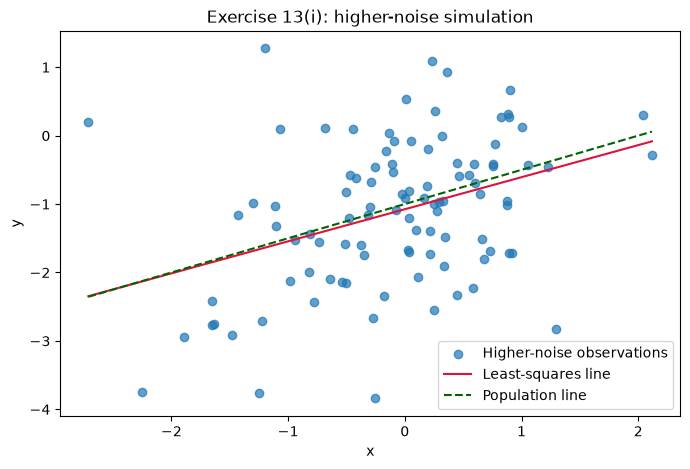

With more noise, the scatter widens, estimates vary more from the true coefficients, and the fitted line is less precise.


In [37]:
# Exercise 13(i)
rng_13_high = np.random.default_rng(1)
x_13_high = rng_13_high.normal(size=100)
eps_13_high = rng_13_high.normal(loc=0, scale=np.sqrt(1.0), size=100)  # higher variance than 0.25
y_13_high = -1 + 0.5 * x_13_high + eps_13_high
fit_13_high = smf.ols("y ~ x", data=pd.DataFrame({"x": x_13_high, "y": y_13_high})).fit()
print(f"High-noise sample variance={eps_13_high.var(ddof=1):.4f}; n={len(y_13_high)}.")
print(f"Estimated coefficients: intercept={fit_13_high.params['Intercept']:.4f}, slope={fit_13_high.params['x']:.4f}; R²={fit_13_high.rsquared:.4f}.")
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(x_13_high, y_13_high, alpha=0.7, label="Higher-noise observations")
x_grid_high = np.linspace(x_13_high.min(), x_13_high.max(), 200)
ax.plot(x_grid_high, fit_13_high.params["Intercept"] + fit_13_high.params["x"] * x_grid_high, color="crimson", label="Least-squares line")
ax.plot(x_grid_high, -1 + 0.5 * x_grid_high, color="darkgreen", linestyle="--", label="Population line")
ax.set(title="Exercise 13(i): higher-noise simulation", xlabel="x", ylabel="y")
ax.legend()
plt.show()
print("With more noise, the scatter widens, estimates vary more from the true coefficients, and the fitted line is less precise.")

### Exercise 13(j)

What are the confidence intervals for β0 and β1 based on the
original data set, the noisier data set, and the less noisy data
set? Comment on your results.

In [38]:
# Exercise 13(j)
intervals_13 = pd.concat(
    {
        "Original variance 0.25": fit_13.conf_int(),
        "Lower variance 0.05": fit_13_low.conf_int(),
        "Higher variance 1.00": fit_13_high.conf_int(),
    },
    names=["Noise setting", "Coefficient"],
)
intervals_13.columns = ["Lower 95%", "Upper 95%"]
display(intervals_13.round(4))
print("The higher-noise intervals are wider and the lower-noise intervals are narrower, reflecting the residual variance; all three use the same n and predictor values.")

Lower 95%  Upper 95%
Noise setting          Coefficient                      
Original variance 0.25 Intercept      -1.1378    -0.9382
                       x               0.3676     0.6010
Lower variance 0.05    Intercept      -1.0616    -0.9724
                       x               0.4408     0.5452
Higher variance 1.00   Intercept      -1.2756    -0.8765
                       x               0.2351     0.7020

The higher-noise intervals are wider and the lower-noise intervals are narrower, reflecting the residual variance; all three use the same n and predictor values.


**Observations / conclusions**

- **(a–c)** I simulated x ~ N(0, 1) and ε ~ N(0, 0.25) with n = 100, so $Y = -1 + 0.5X + \varepsilon$. The vector y has length 100, with $\beta_0 = -1$ and $\beta_1 = 0.5$.
- **(d)** The scatterplot is a clear linear upward trend with moderate noise.
- **(e)** The least-squares estimates are $\hat\beta_0 = -1.038$ and $\hat\beta_1 = 0.484$, very close to the truth, with $R^2 = 0.41$.
- **(f)** The fitted line and the population line almost overlap.
- **(g)** A quadratic term does not improve the fit (p = 0.96), as expected since the truth is linear.
- **(h, i)** With less noise (variance 0.05), the estimates are closer to the truth (−1.017, 0.493) and $R^2 = 0.78$. With more noise (variance 1), they are further off (−1.076, 0.469) and $R^2 = 0.14$.
- **(j)** The 95% CI for $\beta_1$ is [0.441, 0.545] (low noise), [0.368, 0.601] (original) and [0.235, 0.702] (high noise). The intervals widen as the noise grows, and all of them contain the true 0.5.

---

## Exercise 14 · Applied

**Textbook: printed page 132**

This problem focuses on the collinearity problem.

### Exercise 14(a)

Perform the following commands in Python:
rng = np.random.default_rng(10)
x1 = rng.uniform(0, 1, size=100)
x2 = 0.5 * x1 + rng.normal(size=100) / 10
y = 2 + 2 * x1 + 0.3 * x2 + rng.normal(size=100)
The last line corresponds to creating a linear model in which y is
a function of x1 and x2. Write out the form of the linear model.
What are the regression coefficients?

In [39]:
# Exercise 14(a)
rng_14 = np.random.default_rng(10)
x1_14 = rng_14.uniform(0, 1, size=100)
x2_14 = 0.5 * x1_14 + rng_14.normal(size=100) / 10
y_14 = 2 + 2 * x1_14 + 0.3 * x2_14 + rng_14.normal(size=100)
data_14 = pd.DataFrame({"x1": x1_14, "x2": x2_14, "y": y_14})
print("Population model: Y = 2 + 2X₁ + 0.3X₂ + ε, where ε is independent N(0, 1).")
print("True coefficients: β₀=2, β₁=2, β₂=0.3.")

Population model: Y = 2 + 2X₁ + 0.3X₂ + ε, where ε is independent N(0, 1).
True coefficients: β₀=2, β₁=2, β₂=0.3.


### Exercise 14(b)

What is the correlation between x1 and x2? Create a scatterplot
displaying the relationship between the variables.

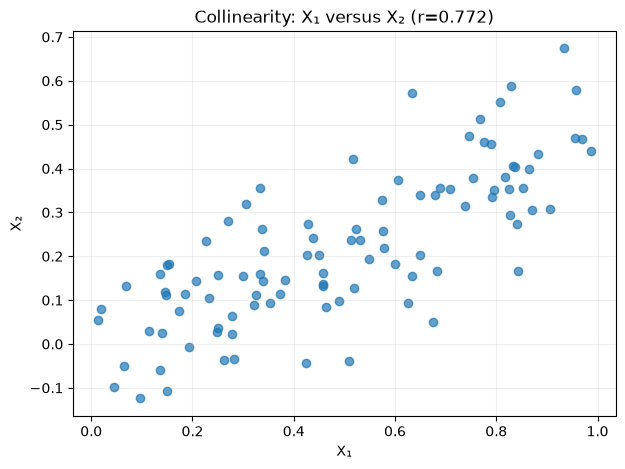

Correlation between x1 and x2: 0.7723; they are strongly positively correlated.


In [40]:
# Exercise 14(b)
corr_14 = np.corrcoef(x1_14, x2_14)[0, 1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(x1_14, x2_14, alpha=0.7)
ax.set(title=f"Collinearity: X₁ versus X₂ (r={corr_14:.3f})", xlabel="X₁", ylabel="X₂")
ax.grid(alpha=0.2)
plt.show()
print(f"Correlation between x1 and x2: {corr_14:.4f}; they are strongly positively correlated.")

### Exercise 14(c)

Using this data, fit a least squares regression to predict y using
x1 and x2. Describe the results obtained. What are ˆβ0, ˆβ1, and
ˆβ2? How do these relate to the true β0, β1, and β2? Can you
reject the null hypothesis H0 : β1 = 0? How about the null
hypothesis H0 : β2 = 0?

In [41]:
# Exercise 14(c)
fit_14c = smf.ols("y ~ x1 + x2", data=data_14).fit()
print(fit_14c.summary())
print("\nEstimated versus true coefficients:")
display(pd.DataFrame({"Estimate": fit_14c.params, "True value": [2, 2, 0.3]}).round(4))
print("The individual tests assess each predictor while holding the other correlated predictor fixed.")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.291
Model:                            OLS   Adj. R-squared:                  0.276
Method:                 Least Squares   F-statistic:                     19.89
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           5.76e-08
Time:                        19:52:58   Log-Likelihood:                -130.62
No. Observations:                 100   AIC:                             267.2
Df Residuals:                      97   BIC:                             275.1
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.9579      0.190     10.319      0.0

,Estimate,True value
Intercept,1.9579,2.0
x1,1.6154,2.0
x2,0.9428,0.3


The individual tests assess each predictor while holding the other correlated predictor fixed.


### Exercise 14(d)

Now fit a least squares regression to predict y using only x1.
Comment on your results. Can you reject the null hypothesis
H0 : β1 = 0?

In [42]:
# Exercise 14(d)
fit_14d = smf.ols("y ~ x1", data=data_14).fit()
print(fit_14d.summary())
print(f"The simple-regression slope for x1 is {fit_14d.params['x1']:.3f} (p={fit_14d.pvalues['x1']:.4g}); its test includes the association that x1 shares with x2.")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.281
Model:                            OLS   Adj. R-squared:                  0.274
Method:                 Least Squares   F-statistic:                     38.39
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           1.37e-08
Time:                        19:52:58   Log-Likelihood:                -131.28
No. Observations:                 100   AIC:                             266.6
Df Residuals:                      98   BIC:                             271.8
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      1.9371      0.189     10.242      0.0

### Exercise 14(e)

Now fit a least squares regression to predict y using only x2.
Comment on your results. Can you reject the null hypothesis
H0 : β1 = 0?

In [43]:
# Exercise 14(e)
fit_14e = smf.ols("y ~ x2", data=data_14).fit()
print(fit_14e.summary())
print(f"The simple-regression slope for x2 is {fit_14e.params['x2']:.3f} (p={fit_14e.pvalues['x2']:.4g}); its test likewise includes the association shared with x1.")

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.222
Model:                            OLS   Adj. R-squared:                  0.214
Method:                 Least Squares   F-statistic:                     27.99
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           7.43e-07
Time:                        19:52:58   Log-Likelihood:                -135.24
No. Observations:                 100   AIC:                             274.5
Df Residuals:                      98   BIC:                             279.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      2.3239      0.154     15.124      0.0

### Exercise 14(f)

Do the results obtained in (c)–(e) contradict each other? Explain
your answer.

In [44]:
# Exercise 14(f)
comparison_14 = pd.DataFrame(
    {
        "Model": ["Multiple: y ~ x1 + x2", "Simple: y ~ x1", "Simple: y ~ x2"],
        "x1 slope": [fit_14c.params["x1"], fit_14d.params["x1"], np.nan],
        "x1 p-value": [fit_14c.pvalues["x1"], fit_14d.pvalues["x1"], np.nan],
        "x2 slope": [fit_14c.params["x2"], np.nan, fit_14e.params["x2"]],
        "x2 p-value": [fit_14c.pvalues["x2"], np.nan, fit_14e.pvalues["x2"]],
        "R-squared": [fit_14c.rsquared, fit_14d.rsquared, fit_14e.rsquared],
    }
).set_index("Model")
display(comparison_14.round(4))
print(
    f"The results do not contradict each other: the multiple model estimates each predictor's "
    f"association while holding the other fixed, whereas each simple model also reflects their "
    f"shared variation (correlation={corr_14:.3f})."
)

,x1 slope,x1 p-value,x2 slope,x2 p-value,R-squared
Model,,,,,
Multiple: y ~ x1 + x2,1.6154,0.0028,0.9428,0.2594,0.2909
Simple: y ~ x1,2.0771,0.0000,NaN,NaN,0.2815
Simple: y ~ x2,NaN,NaN,2.9103,0.0000,0.2222


The results do not contradict each other: the multiple model estimates each predictor's association while holding the other fixed, whereas each simple model also reflects their shared variation (correlation=0.772).


### Exercise 14(g)

Suppose we obtain one additional observation, which was unfortunately mismeasured. We use the function np.concatenate() to np.concatenate()
add this additional observation to each of x1, x2 and y.
x1 = np.concatenate([x1, [0.1]])
x2 = np.concatenate([x2, [0.8]])
y = np.concatenate([y, [6]])
Re-fit the linear models from (c) to (e) using this new data. What
effect does this new observation have on the each of the models?
In each model, is this observation an outlier? A high-leverage
point? Both? Explain your answers.

In [45]:
# Exercise 14(g)
new_observation_14 = pd.DataFrame({"x1": [0.1], "x2": [0.8], "y": [6.0]})
data_14_aug = pd.concat([data_14, new_observation_14], ignore_index=True)

models_14_before = {
    "Multiple (x1 + x2)": fit_14c,
    "Simple (x1)": fit_14d,
    "Simple (x2)": fit_14e,
}
models_14_after = {
    "Multiple (x1 + x2)": smf.ols("y ~ x1 + x2", data=data_14_aug).fit(),
    "Simple (x1)": smf.ols("y ~ x1", data=data_14_aug).fit(),
    "Simple (x2)": smf.ols("y ~ x2", data=data_14_aug).fit(),
}

coefficient_rows_14g = {}
diagnostic_rows_14g = []
for model_name, fit_after in models_14_after.items():
    fit_before = models_14_before[model_name]
    coefficient_rows_14g[model_name] = pd.DataFrame(
        {
            "Estimate before": fit_before.params,
            "Estimate after": fit_after.params,
            "p-value before": fit_before.pvalues,
            "p-value after": fit_after.pvalues,
        }
    )
    influence = fit_after.get_influence()
    last_residual = influence.resid_studentized_external[-1]
    last_leverage = influence.hat_matrix_diag[-1]
    leverage_cutoff = 2 * len(fit_after.params) / len(data_14_aug)
    last_cook = influence.cooks_distance[0][-1]
    diagnostic_rows_14g.append(
        {
            "Model": model_name,
            "Externally studentized residual": last_residual,
            "Leverage": last_leverage,
            "2p/n cutoff": leverage_cutoff,
            "Cook's distance": last_cook,
            "Outlier (|studentized residual| > 3)": abs(last_residual) > 3,
            "High leverage": last_leverage > leverage_cutoff,
        }
    )

print("Coefficient changes after adding the mismeasured observation:")
display(pd.concat(coefficient_rows_14g, names=["Model", "Term"]).round(4))
print("Diagnostics for the added (last) observation:")
display(pd.DataFrame(diagnostic_rows_14g).set_index("Model").round(4))
print(
    "The unusual response can pull the fitted coefficients, while leverage depends on the predictor values. "
    "The table applies |externally studentized residual| > 3 for an outlier and leverage > 2p/n for high leverage."
)

Coefficient changes after adding the mismeasured observation:


Estimate before  Estimate after  p-value before  \
Model              Term                                                         
Multiple (x1 + x2) Intercept           1.9579          2.0618          0.0000   
                   x1                  1.6154          0.8575          0.0028   
                   x2                  0.9428          2.2663          0.2594   
Simple (x1)        Intercept           1.9371          2.0739          0.0000   
                   x1                  2.0771          1.8760          0.0000   
Simple (x2)        Intercept           2.3239          2.2840          0.0000   
                   x2                  2.9103          3.1458          0.0000   

                              p-value after  
Model              Term                      
Multiple (x1 + x2) Intercept         0.0000  
                   x1                0.0690  
                   x2                0.0018  
Simple (x1)        Intercept         0.0000  
                   x1                0.0000  
Simple (x2)        Intercept         0.0000  
                   x2                0.0000

Diagnostics for the added (last) observation:


,Externally studentized residual,Leverage,2p/n cutoff,Cook's distance,Outlier (|studentized residual| > 3),High leverage
Model,,,,,,
Multiple (x1 + x2),2.7837,0.3477,0.0594,1.2880,False,True
Simple (x1),4.1792,0.0303,0.0396,0.2338,True,False
Simple (x2),1.3452,0.1102,0.0396,0.1112,False,True


The unusual response can pull the fitted coefficients, while leverage depends on the predictor values. The table applies |externally studentized residual| > 3 for an outlier and leverage > 2p/n for high leverage.


**Observations / conclusions**

- **(a)** The model is $Y = 2 + 2X_1 + 0.3X_2 + \varepsilon$, with $\beta_0 = 2$, $\beta_1 = 2$, $\beta_2 = 0.3$.
- **(b)** $X_1$ and $X_2$ are strongly correlated (r = 0.77).
- **(c)** The fit with both predictors gives $\hat\beta_0 = 1.96$, $\hat\beta_1 = 1.62$, $\hat\beta_2 = 0.94$. These are poor estimates of 2 and 0.3, with large SEs (0.53 and 0.83). We can reject $H_0: \beta_1 = 0$ (p = 0.003) but **not** $H_0: \beta_2 = 0$ (p = 0.26).
- **(d, e)** On its own, each predictor is highly significant: x1 alone has slope 2.08 (p ≈ 1e-8), and x2 alone has slope 2.91 (p ≈ 7e-7).
- **(f)** These results don't contradict each other. This is **collinearity**: because x1 and x2 carry overlapping information, the multiple regression can't tell their effects apart, so the SEs are inflated. Each simple regression gets credit for the shared variation.
- **(g)** Adding the mismeasured point (x1 = 0.1, x2 = 0.8, y = 6) changes the multiple-regression fit dramatically: x1 becomes non-significant (p = 0.07) and x2 becomes significant (p = 0.002). In the multiple model this point is a **high-leverage** observation (leverage 0.35 vs a cutoff of 0.06) with Cook's distance 1.29, so it is highly influential. In the x1-only model it is an **outlier** (studentized residual 4.2) but not high leverage. In the x2-only model it has high leverage but is not an outlier.

---

## Exercise 15 · Applied

**Textbook: printed page 133**

This problem involves the Boston data set, which we saw in the lab
for this chapter. We will now try to predict per capita crime rate
using the other variables in this data set. In other words, per capita
crime rate is the response, and the other variables are the predictors.

### Exercise 15(a)

For each predictor, fit a simple linear regression model to predict
the response. Describe your results. In which of the models is
there a statistically significant association between the predictor
and the response? Create some plots to back up your assertions.

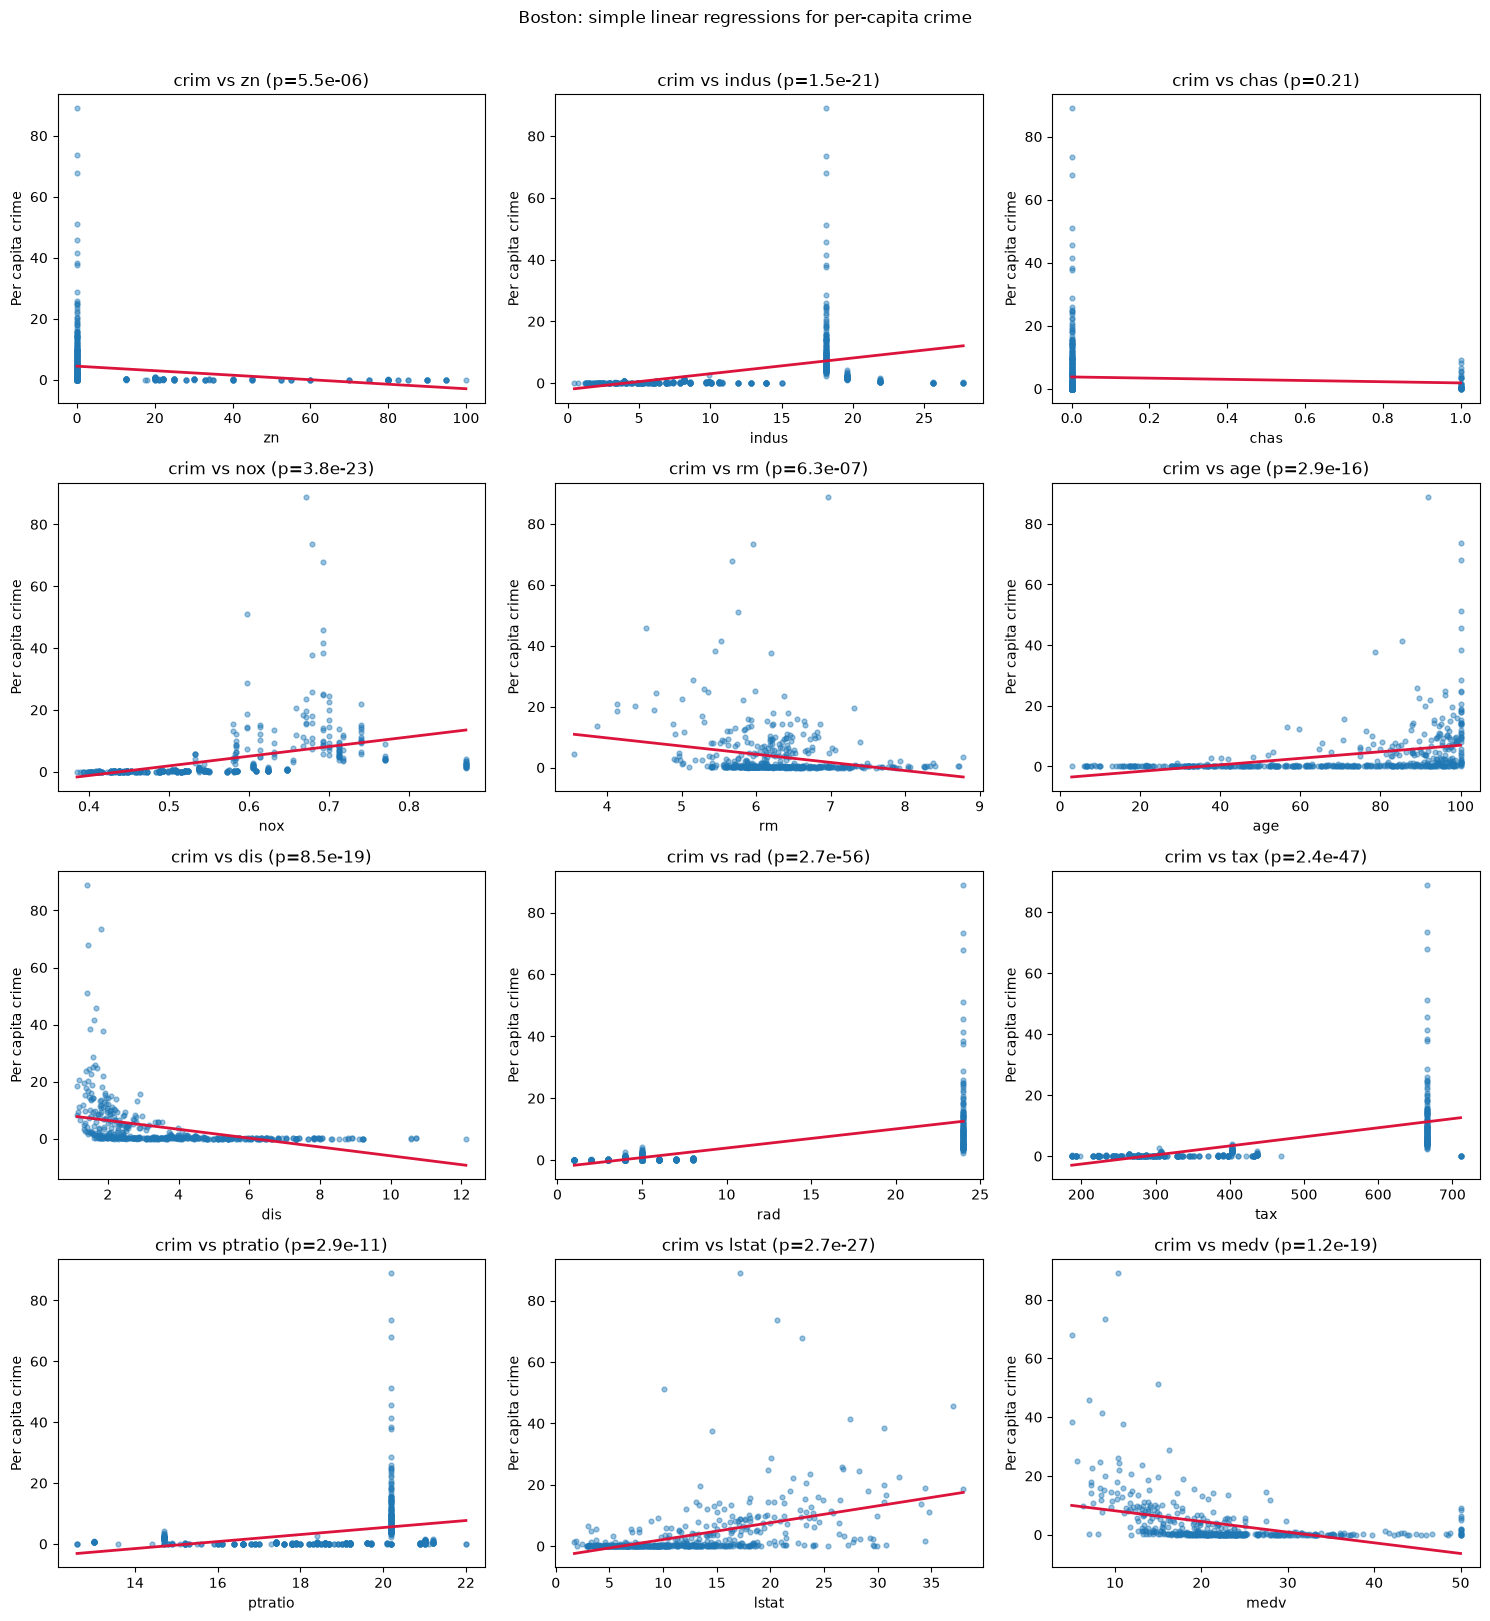

,Slope,p-value,R-squared
Predictor,,,
rad,0.61791,0.00000,0.39126
tax,0.02974,0.00000,0.33961
lstat,0.54880,0.00000,0.20759
nox,31.24853,0.00000,0.17722
indus,0.50978,0.00000,0.16531
medv,-0.36316,0.00000,0.15078
dis,-1.55090,0.00000,0.14415
age,0.10779,0.00000,0.12442
ptratio,1.15198,0.00000,0.08407


Predictors with a significant simple-regression slope at 5%: ['rad', 'tax', 'lstat', 'nox', 'indus', 'medv', 'dis', 'age', 'ptratio', 'rm', 'zn']


In [46]:
# Exercise 15(a)
response_15 = "crim"
predictors_15 = [column for column in boston.columns if column != response_15]
simple_fits_15 = {}
simple_rows_15 = []

ncols_15 = 3
nrows_15 = int(np.ceil(len(predictors_15) / ncols_15))
fig, axes = plt.subplots(nrows_15, ncols_15, figsize=(15, 4 * nrows_15))
axes = np.asarray(axes).ravel()
for ax, predictor in zip(axes, predictors_15):
    fit = smf.ols(f"{response_15} ~ {predictor}", data=boston).fit()
    simple_fits_15[predictor] = fit
    simple_rows_15.append(
        {
            "Predictor": predictor,
            "Slope": fit.params[predictor],
            "p-value": fit.pvalues[predictor],
            "R-squared": fit.rsquared,
        }
    )
    x_values = boston[predictor].to_numpy()
    x_grid = np.linspace(x_values.min(), x_values.max(), 200)
    ax.scatter(x_values, boston[response_15], s=12, alpha=0.45)
    ax.plot(x_grid, fit.params["Intercept"] + fit.params[predictor] * x_grid, color="crimson", linewidth=2)
    ax.set(title=f"{response_15} vs {predictor} (p={fit.pvalues[predictor]:.2g})", xlabel=predictor, ylabel="Per capita crime")
for ax in axes[len(predictors_15):]:
    ax.set_visible(False)
fig.suptitle("Boston: simple linear regressions for per-capita crime", y=1.01)
plt.tight_layout()
plt.show()

simple_results_15 = pd.DataFrame(simple_rows_15).set_index("Predictor").sort_values("p-value")
display(simple_results_15.round(5))
significant_simple_15 = simple_results_15.index[simple_results_15["p-value"] < 0.05].tolist()
print(f"Predictors with a significant simple-regression slope at 5%: {significant_simple_15}")

### Exercise 15(b)

Fit a multiple regression model to predict the response using
all of the predictors. Describe your results. For which predictors
can we reject the null hypothesis H0 : βj = 0?

In [47]:
# Exercise 15(b)
formula_15b = "crim ~ " + " + ".join(predictors_15)
fit_15_multiple = smf.ols(formula_15b, data=boston).fit()
print(fit_15_multiple.summary())
multiple_results_15 = pd.DataFrame(
    {
        "Coefficient": fit_15_multiple.params.drop("Intercept"),
        "p-value": fit_15_multiple.pvalues.drop("Intercept"),
    }
).sort_values("p-value")
display(multiple_results_15.round(5))
significant_multiple_15 = multiple_results_15.index[multiple_results_15["p-value"] < 0.05].tolist()
print(f"At the 5% level, reject H0: beta_j=0 for: {significant_multiple_15}")
print(
    f"The full model has R-squared={fit_15_multiple.rsquared:.3f} "
    f"(adjusted R-squared={fit_15_multiple.rsquared_adj:.3f})."
)

                            OLS Regression Results                            
Dep. Variable:                   crim   R-squared:                       0.449
Model:                            OLS   Adj. R-squared:                  0.436
Method:                 Least Squares   F-statistic:                     33.52
Date:                Tue, 27 Oct 2026   Prob (F-statistic):           2.03e-56
Time:                        19:52:58   Log-Likelihood:                -1655.4
No. Observations:                 506   AIC:                             3337.
Df Residuals:                     493   BIC:                             3392.
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     13.7784      7.082      1.946      0.0

,Coefficient,p-value
rad,0.61247,0.00000
medv,-0.22006,0.00026
dis,-1.01225,0.00037
zn,0.04571,0.01534
nox,-9.95759,0.06037
lstat,0.13880,0.06740
ptratio,-0.30407,0.10339
rm,0.62891,0.30074
tax,-0.00378,0.46576
indus,-0.05835,0.48571


At the 5% level, reject H0: beta_j=0 for: ['rad', 'medv', 'dis', 'zn']
The full model has R-squared=0.449 (adjusted R-squared=0.436).


### Exercise 15(c)

How do your results from (a) compare to your results from (b)?
Create a plot displaying the univariate regression coefficients
from (a) on the x-axis, and the multiple regression coefficients
from (b) on the y-axis. That is, each predictor is displayed as a
single point in the plot. Its coefficient in a simple linear regression model is shown on the x-axis, and its coefficient estimate
in the multiple linear regression model is shown on the y-axis.

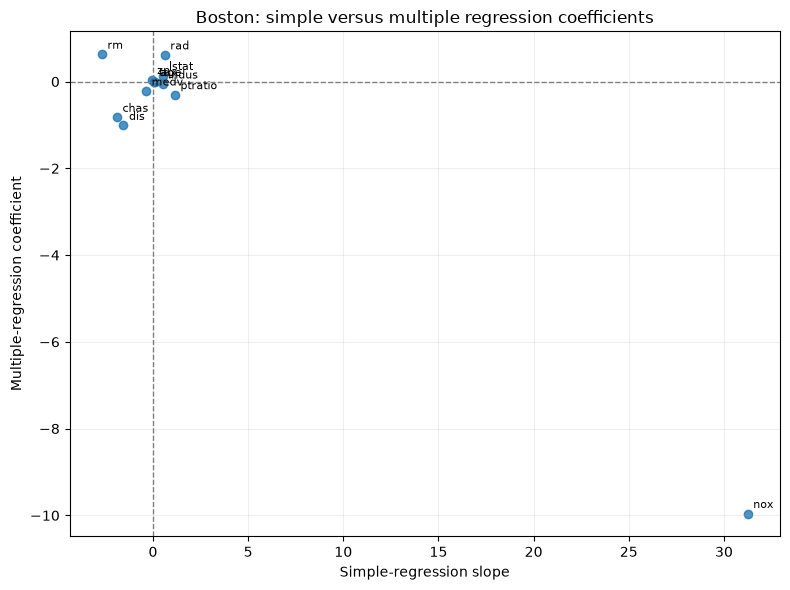

,Simple-regression slope,Multiple-regression coefficient,Sign changed
age,0.10779,-0.00085,True
chas,-1.89278,-0.82538,False
dis,-1.55090,-1.01225,False
indus,0.50978,-0.05835,True
lstat,0.54880,0.13880,False
medv,-0.36316,-0.22006,False
nox,31.24853,-9.95759,True
ptratio,1.15198,-0.30407,True
rad,0.61791,0.61247,False
rm,-2.68405,0.62891,True


The univariate slopes reflect each predictor's overall association with crime; the multiple-regression coefficients are adjusted for the other predictors, so their sizes or signs can change.


In [48]:
# Exercise 15(c)
coefficient_comparison_15 = pd.DataFrame(
    {
        "Simple-regression slope": simple_results_15["Slope"],
        "Multiple-regression coefficient": fit_15_multiple.params.drop("Intercept"),
    }
).dropna()
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(
    coefficient_comparison_15["Simple-regression slope"],
    coefficient_comparison_15["Multiple-regression coefficient"],
    alpha=0.8,
)
for predictor, row in coefficient_comparison_15.iterrows():
    ax.annotate(
        predictor,
        (row["Simple-regression slope"], row["Multiple-regression coefficient"]),
        xytext=(4, 4),
        textcoords="offset points",
        fontsize=8,
    )
ax.axhline(0, color="gray", linewidth=1, linestyle="--")
ax.axvline(0, color="gray", linewidth=1, linestyle="--")
ax.set(
    title="Boston: simple versus multiple regression coefficients",
    xlabel="Simple-regression slope",
    ylabel="Multiple-regression coefficient",
)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

coefficient_comparison_15["Sign changed"] = (
    np.sign(coefficient_comparison_15["Simple-regression slope"])
    != np.sign(coefficient_comparison_15["Multiple-regression coefficient"])
)
display(coefficient_comparison_15.round(5))
print(
    "The univariate slopes reflect each predictor's overall association with crime; "
    "the multiple-regression coefficients are adjusted for the other predictors, so their sizes or signs can change."
)

### Exercise 15(d)

Is there evidence of non-linear association between any of the
predictors and the response? To answer this question, for each
predictor X, fit a model of the form
Y = β0 + β1X + β2X2 + β3X3 + ϵ.

,Added degrees of freedom,Joint nonlinear-term p-value,Test,Cubic R-squared
Predictor,,,,
medv,2,0.00000,tested,0.42020
dis,2,0.00000,tested,0.27782
nox,2,0.00000,tested,0.29698
indus,2,0.00000,tested,0.25966
age,2,0.00000,tested,0.17423
tax,2,0.00001,tested,0.36888
ptratio,2,0.00025,tested,0.11378
rm,2,0.00523,tested,0.06779
zn,2,0.00851,tested,0.05824


Evidence of a nonlinear association at 5% (joint partial F-tests): ['medv', 'dis', 'nox', 'indus', 'age', 'tax', 'ptratio', 'rm', 'zn', 'rad', 'lstat']


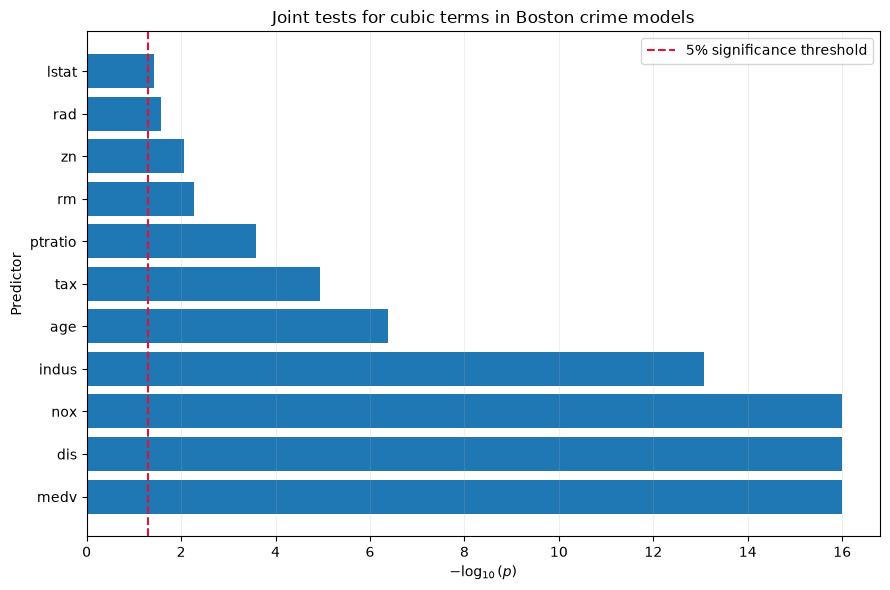

The binary CHAS predictor has no independent squared or cubed terms, so a cubic nonlinearity test is not identifiable.


In [49]:
# Exercise 15(d)
nonlinear_rows_15 = []
nonlinear_fits_15 = {}
for predictor in predictors_15:
    linear_fit = simple_fits_15[predictor]
    # A binary predictor's powers are perfectly redundant, so skip the cubic fit.
    if boston[predictor].nunique() <= 2:
        nonlinear_fits_15[predictor] = linear_fit
        nonlinear_rows_15.append(
            {
                "Predictor": predictor,
                "Added degrees of freedom": 0,
                "Joint nonlinear-term p-value": np.nan,
                "Test": "not testable: binary predictor",
                "Cubic R-squared": linear_fit.rsquared,
            }
        )
        continue

    cubic_formula = f"crim ~ {predictor} + I({predictor} ** 2) + I({predictor} ** 3)"
    cubic_fit = smf.ols(cubic_formula, data=boston).fit()
    nonlinear_fits_15[predictor] = cubic_fit
    comparison = anova_lm(linear_fit, cubic_fit)
    nonlinear_p = comparison.loc[1, "Pr(>F)"]
    nonlinear_rows_15.append(
        {
            "Predictor": predictor,
            "Added degrees of freedom": 2,
            "Joint nonlinear-term p-value": nonlinear_p,
            "Test": "tested",
            "Cubic R-squared": cubic_fit.rsquared,
        }
    )

nonlinear_results_15 = pd.DataFrame(nonlinear_rows_15).set_index("Predictor").sort_values(
    "Joint nonlinear-term p-value", na_position="last"
)
display(nonlinear_results_15.round(5))
significant_nonlinear_15 = nonlinear_results_15.index[
    nonlinear_results_15["Joint nonlinear-term p-value"] < 0.05
].tolist()
print(f"Evidence of a nonlinear association at 5% (joint partial F-tests): {significant_nonlinear_15}")

plot_results_15 = nonlinear_results_15.dropna(subset=["Joint nonlinear-term p-value"]).sort_values(
    "Joint nonlinear-term p-value"
)
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(plot_results_15.index, -np.log10(plot_results_15["Joint nonlinear-term p-value"].clip(lower=1e-16)))
ax.axvline(-np.log10(0.05), color="crimson", linestyle="--", label="5% significance threshold")
ax.set(title="Joint tests for cubic terms in Boston crime models", xlabel="$-\\log_{10}(p)$", ylabel="Predictor")
ax.legend()
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()
print("The binary CHAS predictor has no independent squared or cubed terms, so a cubic nonlinearity test is not identifiable.")

**Observations / conclusions**

- **(a)** In simple regressions, every predictor except `chas` has a significant association with per-capita crime. The strongest are `rad` ($R^2$ = 0.39), `tax` (0.34), `lstat` (0.21) and `nox` (0.18). `chas` (bordering the Charles River) is not significant (p = 0.21).
- **(b)** In the multiple regression ($R^2$ = 0.45), we can reject $H_0: \beta_j = 0$ only for **`zn`, `dis`, `rad` and `medv`** at the 5% level. `nox` and `lstat` are borderline (p ≈ 0.06).
- **(c)** Many coefficients shrink, and several **change sign** (e.g. `nox`: +31 alone vs −10 adjusted; also `rm`, `ptratio`, `indus`, `tax`, `age`, `zn`). The predictors are strongly correlated with each other, especially with `rad` and `tax`. Most of their marginal association with crime reflects that they cluster in the same high-crime, highway-accessible tracts.
- **(d)** Adding squared and cubed terms significantly improves the fit for every quantitative predictor (joint F-test, all p < 0.05). The evidence is strongest for `medv`, `dis`, `nox`, `indus` and `age` (p < 1e-5), so most relationships with crime are clearly **nonlinear**. `chas` is binary, so polynomial terms don't apply to it.